In [1]:
# Importa il modulo os per interagire con il sistema operativo e gestire i percorsi dei file
import os
# Acquisisce il percorso della cartella di lavoro corrente e lo salva nella variabile HOME
HOME = os.getcwd()

In [2]:
# Importa numpy per la gestione efficiente di vettori, matrici e calcoli matematici
import numpy as np
# Importa cv2 (OpenCV) per elaborare e manipolare immagini e flussi video
import cv2
# Importa il sottomodulo pyplot per tracciare e visualizzare grafici statistici
import matplotlib.pyplot as plt
# Importa la classe Image dal pacchetto PIL per aprire e salvare immagini in vari formati
from PIL import Image

***scommentare le righe di codice se lo si vuole caricare***

# Caricare i pesi e istanziare il modello

Per caricare il modello a partire dai pesi che abbiamo salvato (cartella con tutti i pesi salvati: https://drive.google.com/drive/folders/1lDI_gluHMcWwrqNEKMaPsUkHhrhn3e7X?hl=it), ci basta:

In [3]:
# Installa la libreria natsort per l'ordinamento naturale delle stringhe (es. 'video_2' prima di 'video_10')
!pip install natsort
# Importa la funzione natsorted per ordinare le liste in modo naturale
from natsort import natsorted
# Installa ultralytics, pacchetto ufficiale per l'utilizzo del modello YOLOv8
!pip install ultralytics
# Importa il pacchetto ultralytics per l'object detection
import ultralytics
# Verifica i requisiti di sistema e la disponibilità di accelerazione hardware (GPU)
ultralytics.checks()

Ultralytics 8.4.191 🚀 Python-3.13.16 torch-2.11.0+cu130 CUDA:0 (Tesla T4, 14913MiB)
Setup complete ✅ (2 CPUs, 12.7 GB RAM, 42.6/112.6 GB disk)


In [4]:
# Importa la classe YOLO per caricare ed eseguire il modello di Object Detection
from ultralytics import YOLO
# Importa il modulo drive per connettere Google Drive all'ambiente di esecuzione Colab
from google.colab import drive

# Lista contenente i nomi dei file dei pesi preallenati salvati
weigth_list = [
    "pretrained-weights-2026-10-27_18-08-02.pt"
]
# Variabile per abilitare o disabilitare il comportamento degli oggetti speciali
special = "special"
# Sposta l'esecuzione del terminale nella cartella HOME
!cd {HOME}

# Estrae il nome del file dei pesi escludendo l'estensione '.pt'
weigth_filename = weigth_list[0].split('.')[0]

# Definisce la dimensione delle immagini in pixel (larghezza)
TRAINING_WIDTH = 640
# Definisce la dimensione delle immagini in pixel (altezza)
TRAINING_HEIGHT = 640

# Monta lo storage personale di Google Drive nella cartella /content/gdrive
drive.mount('/content/gdrive')
# Copia il file dei pesi dal proprio Google Drive locale alla directory corrente di Colab
!cp /content/gdrive/MyDrive/tesi/{weigth_filename}.pt {HOME}

# Rilascia le risorse di Google Drive e ne esegue lo smontaggio sicuro
drive.flush_and_unmount()

# Inizializza il modello YOLO con i pesi copiati pronti per l'inferenza
model = YOLO(f'{weigth_filename}.pt')

Mounted at /content/gdrive


In [5]:
# Stampa a schermo il nome del file di pesi attualmente in uso per verificarne la correttezza
print(weigth_filename)

pretrained-weights-2026-10-27_18-08-02


Per prima cosa dobbiamo scegliere la dimensione della finestra di immagini da considerare per la valutazione tramite la nostra euristica

In [6]:
# Definisce la dimensione fissa della finestra temporale dei frame da analizzare
window_size = 5

In [7]:
# X, oggetti che possono apparire in un frame (driver-window, driver-seat-belt, passenger-window, passenger-seat-belt, passenger-sun-visor, driver-sun-visor, passenger-grab-handle)
X = model.names
print(X)

{0: 'driver-seat-belt', 1: 'driver-sun-visor', 2: 'driver-window', 3: 'passenger-grab-handle', 4: 'passenger-seat-belt', 5: 'passenger-sun-visor', 6: 'passenger-window'}


In [8]:
# Ritorna la classe dell'oggetto speciale se presente (per classificarlo senza utilizzare alcuna euristica), altrimenti None
# questa funzione è utile per evitare di classificare il frame con un euristica sapendo che un determinato oggetto è caratterizzante di una classe (e.g. passenger-grab-handle)
def has_special_object(X, results, conf_treshold = 0.7, special_objects_names = []):
  # Se l'analisi degli oggetti speciali è disattivata, ritorna immediatamente None
  if special == "nospecial":
    # Ritorna None
    return None
  # Inizializza l'indice per scorrere i risultati
  index = 0
  # Itera su ciascun risultato di rilevamento
  for r in results:
    # Itera sugli indici delle bounding box rilevate
    for index in range(0, len(r.boxes.cls)):
      # Itera sulla lista dei nomi degli oggetti speciali da cercare
      for special_object in special_objects_names:
        # Controlla se l'oggetto speciale corrisponde al nome della classe corrente con confidenza superiore alla soglia
        if special_object in X[int(r.boxes.cls[index])] and float(r.boxes.conf[index]) > conf_treshold:
          # Se l'oggetto appartiene alla classe passeggero, ritorna la stringa passenger
          if "passenger" in special_object:
            # Ritorna passenger
            return "passenger"
          # Altrimenti, se l'oggetto appartiene alla classe conducente, ritorna driver
          elif "driver" in special_object:
            # Ritorna driver
            return "driver"
  # Se nessun oggetto speciale soddisfa i criteri, ritorna None
  return None

In [9]:
# Imposta la soglia di confidenza minima richiesta per convalidare il rilevamento di oggetti speciali
SPECIAL_OBJ_TRESHOLD = 0.8

## Cardinalità delle $k\text{-class-bb}$ (baseline)

In [10]:
# Definizione della funzione baseline che classifica il frame contando semplicemente la cardinalità delle bounding box rilevate
def baseline(results, special_objects_names):
  # Numero di bounding box di oggetti della classe driver riconosciuti nel frame corrente dal modello
  driver_class_bb_cardinality = 0
  # Numero di bounding box di oggetti della classe passenger riconosciuti nel frame corrente dal modello
  passenger_class_bb_cardinality = 0

  # Iteriamo sui risultati restituiti dal modello YOLO per analizzare le classi dei box predetti
  for r in results:
    for c in r.boxes.cls:
      # si noti che basta controllare se la classe è contenuta come sottostringa (e.g. driver-window, driver-seat-belt, driver-handle, etc),
      if "driver" in X[int(c)]:
        driver_class_bb_cardinality += 1
      elif "passenger" in X[int(c)]:
        passenger_class_bb_cardinality += 1
  # classifichiamo il frame confrontando le due cardinalità calcolate
  if driver_class_bb_cardinality > passenger_class_bb_cardinality:
    return "driver"
  elif passenger_class_bb_cardinality > driver_class_bb_cardinality:
    return "passenger"
  else:
    return "none"

## MCS

In [11]:
# Calcola la somma dei valori di confidenza per le classi driver e passenger
def compute_sum_confidence(X_k, results):
  # Inizializza la somma della confidenza per la classe driver
  driver_bb_conf = 0
  # Inizializza la somma della confidenza per la classe passenger
  passenger_bb_conf = 0

  # Inizializza l'indice per tracciare le corrispondenze
  index = 0
  # Scorre tutti i risultati restituiti dal modello
  for r in results:
    # Scorre le confidenze associate a ciascuna bounding box
    for c in r.boxes.conf:
      # Se la classe dell'oggetto contiene la parola driver, somma la confidenza
      if "driver" in X_k[index]:
        # Incrementa la confidenza cumulativa per il conducente
        driver_bb_conf += float(c)
      # Altrimenti se contiene la parola passenger, somma la confidenza
      elif "passenger" in X_k[index]:
        # Incrementa la confidenza cumulativa per il passeggero
        passenger_bb_conf += float(c)
      # Incrementa l'indice della bounding box sotto esame
      index += 1
  # Ritorna la tupla contenente la confidenza del conducente e del passeggero
  return (driver_bb_conf, passenger_bb_conf)

# Computa il multiinsieme X_k contenente elementi in X che compaiono nell'immagine k
def compute_X_k(X, results):
  # Inizializza una lista vuota per contenere i nomi delle classi rilevate
  X_k = []
  # Itera sui risultati per estrarre le classi
  for r in results:
    # Popoliamo X_k con le etichette testuali delle classi
    for c in r.boxes.cls:
      # Aggiunge alla lista il nome della classe corrispondente
      X_k.append(X[int(c)])
  # Ritorna la lista dei nomi delle classi rilevate
  return X_k

# Esegue la classificazione MCS confrontando la somma delle confidenze delle classi
def MCS(results, special_objects_names):
  # Estrae la lista delle classi rilevate nel frame
  X_k = compute_X_k(X, results)
  # Calcola la somma dei punteggi di confidenza per conducente e passeggero
  driver_bb_conf, passenger_bb_conf = compute_sum_confidence(X_k, results)

  # Confronta i punteggi per classificare il frame
  if driver_bb_conf > passenger_bb_conf:
    # Ritorna driver
    return "driver"
  # Se la confidenza del passeggero è maggiore di quella del conducente
  elif passenger_bb_conf > driver_bb_conf:
    # Ritorna passenger
    return "passenger"
  # Se i punteggi sono identici o non ci sono rilevamenti
  else:
    # Ritorna none
    return "none"

## MCS with treshold activation T

In [12]:
# Esegue la classificazione MCS con soglia di attivazione per discriminare i casi dubbi
def MCS_with_treshold_activation(results, special_objects_names, T=0.4):
  # Estrae la lista delle classi rilevate nel frame
  X_k = compute_X_k(X, results)
  # Calcola le somme delle confidenze per conducente e passeggero
  driver_bb_conf, passenger_bb_conf = compute_sum_confidence(X_k, results)

  # Verifica se la differenza assoluta tra i punteggi è superiore alla soglia T
  if (abs(driver_bb_conf - passenger_bb_conf) > T):
    # Confronta direttamente le somme per decidere la classe
    if driver_bb_conf > passenger_bb_conf:
      # Ritorna driver
      return "driver"
    # Se la confidenza del passeggero è maggiore
    elif passenger_bb_conf > driver_bb_conf:
      # Ritorna passenger
      return "passenger"
    # In caso di parità
    else:
      # Ritorna none
      return "none"
  # Se la differenza non supera la soglia, ripiega sul metodo baseline
  else:
    # Chiama e ritorna il risultato della funzione baseline
    return baseline(results, special_objects_names)

# Statistiche sulla precisione del modello
Per poter studiare come si comporta il modello (su diverse euristiche) al variare della dimensione delle finestre e con il passare del tempo, abbiamo bisogno di introdurre dei "cronometri":
- fissiamo una lista ```classification_confidence_list``` che contiene valori percentuali (quindi nell'intervallo $[0,1]$) di precisioni di cui vogliamo monitorare il tempo necessario per raggiungerla
- fissiamo un finestra dalla quale iniziare a monitorare le precisioni (nel codice ```start_recording_window```)
- teniamo un contatore delle window già considerate (```window_counter```)
- se viene raggiunta la precisione, andiamo a memorizzare il tempo intercorso dall'inizio del monitoraggio (```time.time() - start_time```).

Come viene calcolata la precisione?
La precisione viene calcolata sulle finestre, questo viene fatto in accordo a come sono state calcolate le precisioni per effettuare questo tipo di analisi anche nel lavoro precedente (Capitolo 6, Risultati):

*L'analisi dei risultati in questo punto è stata
effettuata nel seguente modo: per ogni video ho considerato le prime  windows in sequenza (per ogni numero di frame) e ho valutato l'accuracy su di
esse. Nel caso in cui l'accuracy si è rivelata uguale o superiore alla percentuale K mi sono fermato e ho annotato dati e percentuali*

In [13]:
# WARNING: dobbiamo fissare gli fps e i secondi che sono condivisi da tutti i video n del nostro dataset
# Numero totale di video inclusi nel dataset per la fase di test
n = 15
# Numero di frame estratti ed analizzati per ogni secondo di video
fps = 1
# Durata temporale standard espressa in secondi di ciascun filmato
sec = 10

# Calcolo del numero complessivo di fotogrammi (frame) che compongono un singolo video
total_frames = fps * sec

In [14]:
# Calcola e stampa l'istante temporale (in secondi fittizi) sommando la finestra iniziale di record ad altri 4 frame successivi
print(1/fps * 20 + 1/fps + 1/fps + 1/fps + 1/fps)

24.0


In [15]:
import time

# Euristiche
baseline_name = "baseline"
MCS_name = "MCS"
MCSwT_name = "MCSwT"
special_objects_names = ["passenger-grab-handle"]

# Lista delle euristiche per la classificazione dei frame da utilizzare
heuristics = [ baseline_name, MCS_name, MCSwT_name ]

def get_window_classifications(frame_classifications, heuristics, current_frame, counter):
  # Dizionario dei frame classificati come "driver" nella finestra
  window_driver_classifications = {}

  window_driver_classifications[baseline_name] = 0
  window_driver_classifications[MCS_name] = 0
  window_driver_classifications[MCSwT_name] = 0

  # Dizionario dei frame classificati come "passenger" nella finestra
  window_passenger_classifications = {}

  window_passenger_classifications[baseline_name] = 0
  window_passenger_classifications[MCS_name] = 0
  window_passenger_classifications[MCSwT_name] = 0

  for heuristic in heuristics:
    if frame_classifications[heuristic][current_frame-counter] == "driver":
      window_driver_classifications[heuristic] += 1
    elif frame_classifications[heuristic][current_frame-counter] == "passenger":
      window_passenger_classifications[heuristic] += 1
  return (window_driver_classifications, window_passenger_classifications)

def update_classifications(window_driver_classifications, driver_frames, window_passenger_classifications, passenger_frames, heuristics, none_frames):
  for heuristic in heuristics:
    # Applichiamo la politica per la classificazione del frame in osservazione tenendo in considerazione la finestra di frame precedenti
    if window_driver_classifications[heuristic] > window_passenger_classifications[heuristic]:
      # aggiorniamo i frame classificati come "driver"
      driver_frames[heuristic] += 1
    elif window_passenger_classifications[heuristic] > window_driver_classifications[heuristic]:
      # aggiorniamo i frame classificati come "passenger"
      passenger_frames[heuristic] += 1
    else:
      none_frames[heuristic] += 1
  return (driver_frames, passenger_frames, none_frames)

def compute_video_class(driver_frames, passenger_frames, heuristics):
  preds = {}

  for heuristic in heuristics:
    if driver_frames[heuristic] > passenger_frames[heuristic]:
      preds[heuristic] = "driver"
    elif passenger_frames[heuristic] > driver_frames[heuristic]:
      preds[heuristic] = "passenger"
  return preds

def get_classification_confidence(driver_frames, passenger_frames, heuristics, window_counter):
  # Window accuracy for each heuristic
  accuracy = {}

  for heuristic in heuristics:
    maximum_predictions_class = "passenger" if passenger_frames[heuristic] > driver_frames[heuristic] else "driver"
    if maximum_predictions_class == "passenger":
      accuracy[heuristic] = passenger_frames[heuristic] / window_counter
    elif maximum_predictions_class == "driver":
      accuracy[heuristic] = driver_frames[heuristic] / window_counter

  return accuracy

def compute_accuracy(driver_frames, passenger_frames, none_frames, real_video_class, heuristics, frame_counter):
  # Accuracy for each heuristic
  accuracy = {}

  for heuristic in heuristics:
    frame_counter_without_none = frame_counter - none_frames[heuristic]
    if real_video_class == "passenger":
      accuracy[heuristic] = passenger_frames[heuristic] / frame_counter_without_none
    elif real_video_class == "driver":
      accuracy[heuristic] = driver_frames[heuristic] / frame_counter_without_none

  return accuracy


def predict_on_one_video(video_directory, classification_confidence_list = [0.5, 0.6, 0.7, 0.8, 0.9], start_recording_window = 2):
  print(f"Predict on: {video_directory}")
  # Contatore delle window analizzate
  window_counter = 0

  # Precisione del modello sulle finestre e tempo necessario per raggiungerla
  frame_accuracy = {}
  for k in range(0, len(classification_confidence_list)):
    frame_accuracy[k] = {}

  fails = {}
  for k in range (0, len(classification_confidence_list)):
    fails[k] = {}

  # Classe del video
  real_video_class = ""

  # Dizionario dei numeri di frame classificati come "driver"
  driver_frames = {}

  driver_frames[baseline_name] = 0
  driver_frames[MCS_name] = 0
  driver_frames[MCSwT_name] = 0

  # Dizionario dei numeri di frame classificati come "passenger"
  passenger_frames = {}

  passenger_frames[baseline_name] = 0
  passenger_frames[MCS_name] = 0
  passenger_frames[MCSwT_name] = 0

  none_frames = {}

  none_frames[baseline_name] = 0
  none_frames[MCS_name] = 0
  none_frames[MCSwT_name] = 0

  # Dizionario che contiene le classificazioni dei frame
  frame_classifications = {}

  frame_classifications[baseline_name] = []
  frame_classifications[MCS_name] = []
  frame_classifications[MCSwT_name] = []

  directory_files = natsorted(os.listdir(video_directory))
  for filename in directory_files:
    if filename.endswith(".class"):
      real_video_class = filename[:-6]
  print("Real " + real_video_class)
  # Indice del frame sotto osservazione
  frame_counter = 0

  frame_sec = 1 / fps
  for filename in directory_files:
    if ".ipynb_checkpoints" in filename or filename.endswith(".class") or filename.endswith(".xml"):
      continue
    # Numero di elementi del conducente riconosciuti nel frame corrente
    driver_objects = 0
    # Numero di elementi del passeggero riconosciuti nel frame corrente
    passenger_objects = 0
    # opencv converte l'immagine per fare in modo che utilizzi lo spazio BGR, che sarebbe proprio RGB in cui 'Red' e 'Blue' sono scambiati.
    img = cv2.imread(f"{video_directory}/{filename}")
    # dobbiamo riconvertire l'immagine per fare modo che utilizzi RGB: il nostro modello è stato allenato con un dataset di immagini RGB
    img = cv2.cvtColor(img, cv2.COLOR_BGR2RGB)
    # ridimensioniamo le immagini per avere un risultato più preciso, con la stessa dimensione che abbiamo utilizzato per le immagini di training
    img = cv2.resize(img, (TRAINING_WIDTH, TRAINING_HEIGHT))

    # diamo in input al modello il frame analizzato
    results = model(f"{video_directory}/{filename}", conf=0.2)
    index = 0

    # prima di applicare le euristiche, controlliamo le maniglie
    if has_special_object(X, results, SPECIAL_OBJ_TRESHOLD, special_objects_names) != None:
      for heuristic in heuristics:
        frame_classifications[heuristic].append("passenger")
    else:
      frame_classifications[baseline_name].append(baseline(results, special_objects_names))
      frame_classifications[MCS_name].append(MCS(results, special_objects_names))
      frame_classifications[MCSwT_name].append(MCS_with_treshold_activation(results, special_objects_names, 0.2))

    if frame_counter > (window_size - 1):

      # Ciclo per analizzare la finestra di frame precedenti
      for counter in range(1, window_size+1):
        window_driver_classifications, window_passenger_classifications = get_window_classifications(frame_classifications, heuristics, frame_counter, counter)
      driver_frames, passenger_frames, none_frames = update_classifications(window_driver_classifications, driver_frames, window_passenger_classifications, passenger_frames, heuristics, none_frames)

      # window_counter = frame_counter + 1 - window_size
      window_counter += 1
      frame_sec += 1 / fps
      if (window_counter >= start_recording_window):
        accuracy = get_classification_confidence(driver_frames, passenger_frames, heuristics, window_counter)
        end = time.time()
        for heuristic in heuristics:
          for k in range(0, len(classification_confidence_list)):
            if frame_accuracy[k].get(heuristic) == None:
              if accuracy[heuristic] > classification_confidence_list[k]:
                end = time.time()
                fails[k][heuristic] = window_counter
                frame_accuracy[k][heuristic] = (accuracy[heuristic], frame_sec)
    frame_counter += 1
    # quando abbiamo ormai scannerizzato tutto il video, andiamo a vedere le percentuali di fallimento sull'accuracy e riempiamo le accuracy non raggiunte con il valore sec (durata del video)
    if frame_counter == (total_frames - 1):
      print("entrato in fails")
      for heuristic in heuristics:
        for k in range(0, len(classification_confidence_list)):
          if frame_accuracy[k].get(heuristic) == None:
            fails[k][heuristic] = 1
            frame_accuracy[k][heuristic] = (accuracy[heuristic], sec)
          else:
            fails[k][heuristic] = 0
      print(fails)


  pred_video_class = compute_video_class(driver_frames, passenger_frames, heuristics)
  print("Pred class: ", pred_video_class)
  print("\n")
  return (real_video_class, pred_video_class, frame_classifications, frame_accuracy, driver_frames, passenger_frames, none_frames, fails)

# Verso i test e i confronti delle euristiche: i dati
Per confrontare tra di loro le varie euristiche abbiamo bisogno di dati su cui testarle, per questa ragione dobbiamo dare in pasto diversi video.

Ho deciso di strutturare il codice in modo tale che la variabile ```${HOME}/videos_directory``` contenga il percorso alla directory che a sua volta conterrà $n$ directory che a loro volta conterranno immagini di video preprocessati in modo tale che vengano condivise le seguenti specifiche:
- durata del video: ```sec``` secondi
- immagini per secondo: ```fps``` immagini

Inoltre per ognuna delle $n$ directory deve essere previsto un file posto all'interno di esse che indichi la classe $c$ del video (questo file deve essere nominato secondo la seguente convenzione: $\text{c.class}$, dove $c$ è la sua classe).

Un esempio di struttura delle directory potrebbe essere la seguente:
```
${HOME}/videos_directory
  video_1
    driver.class
    video_1_frame_1.png
    video_1_frame_2.png
    video_1_frame_3.png
  video_2
    passenger.class
    video_2_frame_1.png
    video_2_frame_2.png
    video_2_frame_3.png
  video_3
    passenger.class
    video_3_frame_1.png
    video_3_frame_2.png
    video_3_frame_3.png
  video_4
    driver.class
    video_4_frame_1.png
    video_4_frame_2.png
    video_4_frame_3.png
```

# Verso i test e i confronti delle euristiche: carichiamo i video
Per preparare i dati in modo tale che soddisfino la struttura precedentemente indicata, ho scritto un paio di script in bash, per rendere il tutto più veloce all'aumentare dei dati:

*trim_to_X_seconds.sh*:
```
#!/bin/bash

usage() { echo "Usage: $0 [-h] [-s --seconds <seconds>] [-d --dirname <string>]" 1>&2; exit 1; }

while getopts "d:s:-:" option; do
        if [ "$option" = "-" ]; then
                OPT="${OPTARG%%=*}"
                OPTARG="${OPTARG#$OPT}"
                OPTARG="${OPTARG#=}"
        fi
        case "${option}" in
                d | dirname)
                        dirname=${OPTARG}
                        ;;
                s | seconds)
                        seconds=${OPTARG}
                        ;;
                *)
                        seconds="5"
                        ;;
        esac
done

echo $dirname

if [[ -z "${dirname}" ]]
then
        usage
fi

# creating
output_dir="${dirname}_trimmed_to_${seconds}_secs"
mkdir ${output_dir}
for filename in "${dirname}"/*.mp4; do
        ffmpeg -ss 00:00:00 -i $filename -c copy -t 00:00:0${seconds} "${output_dir}/${filename##*/}"
done


```

*convert_multiple_videos.sh*:

```
#!/bin/bash
usage() { echo "Usage: $0 [-h] [-d --dirname <string>] [-f <integer>]" 1>&2; exit 1; }

while getopts "d:f:-:" option; do
        if [ "$option" = "-" ]; then
                OPT="${OPTARG%%=*}"
                OPTARG="${OPTARG#$OPT}"
                OPTARG="${OPTARG#=}"
        fi
        case "${option}" in
                d | dirname)
                        dirname=${OPTARG}
                        ;;
		f)
			fps=${OPTARG}
			;;
                *)
			usage
                        ;;
        esac
done
if [ -z "${fps}" ] || [ -z "${dirname}" ]
then
	usage
fi
folder="${dirname}-${fps}fps-images"
mkdir $folder
for filename in $dirname/*.mp4; do
	mkdir "${folder}/${filename##*/}"
	ffmpeg -i $filename -vf fps=$fps "${folder}/${filename##*/}/${filename##*/}-%d.png"
done
```

Una volta processati i nostri video con questi script, ci basta creare un file zip con il comando ```zip -r <zip file name> <directory>``` e caricarlo su questo ambiente Colab.

In [16]:
!cd {HOME}
# Carichiamo lo zip contenente i dati
drive.mount('/content/gdrive')
!cp /content/gdrive/MyDrive/tesi/videos-for-inference.zip {HOME}

# Unzippiamo
!unzip videos-for-inference.zip

drive.flush_and_unmount()

Mounted at /content/gdrive
Archive:  videos-for-inference.zip
   creating: videos-for-inference/
   creating: videos-for-inference/set7-driver-day-obj-similarcolor/
  inflating: videos-for-inference/set7-driver-day-obj-similarcolor/set7-driver-day-obj-similarcolor-5_png_jpg.rf.7d3f113fa4a189e8690a2dfd13edbf1b.jpg.jpg  
  inflating: videos-for-inference/set7-driver-day-obj-similarcolor/set7-driver-day-obj-similarcolor-6_png_jpg.rf.0136a32d08e232c9e4385e806bb3b4bb.jpg.jpg  
  inflating: videos-for-inference/set7-driver-day-obj-similarcolor/set7-driver-day-obj-similarcolor-3_png_jpg.rf.538a261331b10f168c87431881a6f454.jpg.jpg  
  inflating: videos-for-inference/set7-driver-day-obj-similarcolor/set7-driver-day-obj-similarcolor-9_png_jpg.rf.48152bb2bffe903d3aac016cdf173d35.jpg.jpg  
  inflating: videos-for-inference/set7-driver-day-obj-similarcolor/set7-driver-day-obj-similarcolor-10_png_jpg.rf.d2957a334edfeff28ca9f3f7fd09d72a.jpg.jpg  
  inflating: videos-for-inference/set7-driver-day-obj-

In [17]:
# Esegue il conteggio del numero di file e cartelle estratte all'interno della directory dei video di test
!ls videos-for-inference | wc -l

15


In [18]:
# Directory contenente le n directory dei singoli video pronti per la classificazione
videos_directory = f"{HOME}/videos-for-inference"

In [19]:
# Inizializza la lista vuota che conterrà le previsioni di classificazione finali per ogni video
predictions = []

# Definisce le diverse soglie di confidenza (espresse in frazioni) di cui tracciare i tempi di raggiungimento
classification_confidence_list = [ 0.4, 0.75, 0.8, 0.85, 0.9, 0.95, 0.99]

# Imposta il numero minimo di finestre da analizzare prima di iniziare a monitorare ed esportare le metriche
start_recording_window = 2

# Inizializza un contatore incrementale per tenere traccia dell'indice del video correntemente processato
index = 0

# Cicla sulle singole directory dei video ordinate in modo naturale per garantire la sequenzialità
for video_directory in natsorted(os.listdir(videos_directory)):
  # Chiama la funzione di predizione sul singolo video accumulando il set di risultati nell'apposita lista
  predictions.append(predict_on_one_video(f"{videos_directory}/{video_directory}", classification_confidence_list, start_recording_window=start_recording_window))

  # Incrementa il contatore dell'indice per passare alla verifica del video successivo
  index += 1

  # Interrompe anticipatamente il ciclo principale se abbiamo raggiunto il numero massimo n di video previsto
  if index == n:
    # Esce dal ciclo di elaborazione dei video
    break

Predict on: /content/videos-for-inference/set5-driver-day-obj-similarcolor
Real driver

image 1/1 /content/videos-for-inference/set5-driver-day-obj-similarcolor/set5-driver-day-obj-similarcolor-1_png_jpg.rf.2b14ffb28d2dcd51d1fc47eb397bd385.jpg.jpg: 640x640 1 driver-seat-belt, 1 driver-sun-visor, 1 driver-window, 29.2ms
Speed: 71.0ms preprocess, 29.2ms inference, 32.8ms postprocess per image at shape (1, 3, 640, 640)

image 1/1 /content/videos-for-inference/set5-driver-day-obj-similarcolor/set5-driver-day-obj-similarcolor-2_png_jpg.rf.bb59149b7e74038821c3d0e258ce419d.jpg.jpg: 640x640 1 driver-seat-belt, 1 driver-sun-visor, 1 driver-window, 30.4ms
Speed: 1.3ms preprocess, 30.4ms inference, 1.8ms postprocess per image at shape (1, 3, 640, 640)

image 1/1 /content/videos-for-inference/set5-driver-day-obj-similarcolor/set5-driver-day-obj-similarcolor-3_png_jpg.rf.7e27e60103a3612b09596a6807afa0fd.jpg.jpg: 640x640 1 driver-seat-belt, 1 driver-sun-visor, 1 driver-window, 29.1ms
Speed: 1.1ms pr

In [20]:
# Estrae l'associazione indice-nome delle classi apprese dal modello YOLO
X = model.names
# Stampa l'elenco dei nomi delle classi rilevabili dal modello
print(X)

{0: 'driver-seat-belt', 1: 'driver-sun-visor', 2: 'driver-window', 3: 'passenger-grab-handle', 4: 'passenger-seat-belt', 5: 'passenger-sun-visor', 6: 'passenger-window'}


# Verso i test e i confronti delle euristiche: i risultati
A questo punto abbiamo i risultati prodotti dal modello utilizzando le diverse euristiche.

Dobbiamo ottenere degli oggetti che possano essere facilmente confrontabili tra di loro.


In [21]:
# Converte la lista di predizioni totali in un array multidimensionale NumPy per facilitarne l'indicizzazione e il slicing
predictions_array = np.array(predictions)

In [22]:
# Inizializza array NumPy vuoti per memorizzare le predizioni frame per frame di ciascuna euristica
baseline_predictions = np.empty(0)
# Inizializza l'array per le predizioni MCS
MCS_predictions = np.empty(0)
# Inizializza l'array per le predizioni MCSwT
MCSwT_predictions = np.empty(0)

# Inizializza l'array NumPy vuoto per memorizzare le classi reali dei video
real_video_classes = np.empty(0)

# Inizializza gli array per le classi video globali predette dalle tre euristiche
pred_video_classes_baseline = np.empty(0)
# Inizializza l'array per le classi predette da MCS
pred_video_classes_MCS = np.empty(0)
# Inizializza l'array per le classi predette da MCSwT
pred_video_classes_MCSwT = np.empty(0)

# Inizializza i dizionari per memorizzare le accuratezze calcolate ad ogni livello di confidenza
accuracy_baseline = {}
# Inizializza il dizionario delle accuratezze per MCS
accuracy_MCS = {}
# Inizializza il dizionario delle accuratezze per MCSwT
accuracy_MCSwT = {}

# Inizializza i dizionari per registrare i tempi di attivazione corrispondenti
times_baseline = {}
# Inizializza il dizionario dei tempi per MCS
times_MCS = {}
# Inizializza il dizionario dei tempi per MCSwT
times_MCSwT = {}

# Inizializza i dizionari per contare il numero di mancati raggiungimenti delle soglie
fails_baseline = {}
# Inizializza il dizionario dei fallimenti per MCS
fails_MCS = {}
# Inizializza il dizionario dei fallimenti per MCSwT
fails_MCSwT = {}

# Cicla su ciascun indice delle soglie di confidenza impostate
for k in range(0, len(classification_confidence_list)):
  # Inizializza un array vuoto per raccogliere le accuratezze della baseline alla soglia k
  accuracy_baseline[k] = np.empty(0)
  # Inizializza l'array delle accuratezze per MCS alla soglia k
  accuracy_MCS[k] = np.empty(0)
  # Inizializza l'array delle accuratezze per MCSwT alla soglia k
  accuracy_MCSwT[k] = np.empty(0)

  # Inizializza l'array per i tempi di attivazione della baseline con tipo float alla soglia k
  times_baseline[k] = np.empty(0, dtype='f')
  # Inizializza l'array dei tempi per MCS alla soglia k
  times_MCS[k] = np.empty(0)
  # Inizializza l'array per i tempi di attivazione di MCSwT con tipo float alla soglia k
  times_MCSwT[k] = np.empty(0, dtype='f')

  # Imposta a zero il contatore dei fallimenti iniziale della baseline alla soglia k
  fails_baseline[k] = 0
  # Imposta a zero il contatore dei fallimenti iniziale di MCS alla soglia k
  fails_MCS[k] = 0
  # Imposta a zero il contatore dei fallimenti iniziale di MCSwT alla soglia k
  fails_MCSwT[k] = 0

# Scorre l'array contenente i dati di predizione estratti da tutti i video
for pred in predictions_array:
  # Concatena le predizioni dei singoli frame per l'euristica baseline
  baseline_predictions = np.append(baseline_predictions, pred[2][baseline_name])
  # Concatena le predizioni dei singoli frame per l'euristica MCS
  MCS_predictions = np.append(MCS_predictions, pred[2][MCS_name])
  # Concatena le predizioni dei singoli frame per l'euristica MCSwT
  MCSwT_predictions = np.append(MCSwT_predictions, pred[2][MCSwT_name])

  # Salva la classe reale del video corrente nell'apposito array
  real_video_classes = np.append(real_video_classes, pred[0])
  # Salva la classe globale predetta dalla baseline per il video corrente
  pred_video_classes_baseline = np.append(pred_video_classes_baseline, pred[1].get(baseline_name))
  # Salva la classe globale predetta da MCS per il video corrente
  pred_video_classes_MCS = np.append(pred_video_classes_MCS, pred[1].get(MCS_name))
  # Salva la classe globale predetta da MCSwT per il video corrente
  pred_video_classes_MCSwT = np.append(pred_video_classes_MCSwT, pred[1].get(MCSwT_name))

  # Itera sulle diverse soglie di confidenza definite nella configurazione
  for k in range(0, len(classification_confidence_list)):
    # Accumula i fallimenti registrati per la baseline alla soglia k
    fails_baseline[k] = fails_baseline[k] + pred[7][k].get(baseline_name)
    # Accumula i fallimenti registrati per MCSwT alla soglia k
    fails_MCSwT[k] = fails_MCSwT[k] + pred[7][k].get(MCSwT_name)
    # Accumula i fallimenti registrati per MCS alla soglia k
    fails_MCS[k] = fails_MCS[k] + pred[7][k].get(MCS_name)

    # Salva il valore di accuratezza della baseline registrato alla soglia k
    accuracy_baseline[k] = np.append(accuracy_baseline[k], pred[3][k].get(baseline_name)[0])
    # Salva il tempo impiegato dalla baseline registrato alla soglia k
    times_baseline[k] = np.append(times_baseline[k], pred[3][k].get(baseline_name)[1])

    # Salva il valore di accuratezza di MCS registrato alla soglia k
    accuracy_MCS[k] = np.append(accuracy_MCS[k], pred[3][k].get(MCS_name)[0])
    # Salva il tempo impiegato da MCS registrato alla soglia k
    times_MCS[k] = np.append(times_MCS[k], pred[3][k].get(MCS_name)[1])

    # Salva il valore di accuratezza di MCSwT registrato alla soglia k
    accuracy_MCSwT[k] = np.append(accuracy_MCSwT[k], pred[3][k].get(MCSwT_name)[0])
    # Salva il tempo impiegato da MCSwT registrato alla soglia k
    times_MCSwT[k] = np.append(times_MCSwT[k], pred[3][k].get(MCSwT_name)[1])

In [23]:
# Importiamo la libreria pandas per creare tabelle riassuntive dei dati
import pandas as pd
# Importiamo Counter per contare in modo efficiente le occorrenze delle etichette
from collections import Counter

# Conteggio dei frame classificati per l'euristica di baseline
baseline_predictions_class_counts = Counter(baseline_predictions)
df = pd.DataFrame.from_dict(baseline_predictions_class_counts, orient='index')
print("baseline_predictions_class_counts", df)

# Conteggio dei frame classificati per l'euristica MCS
MCS_predictions_class_counts = Counter(MCS_predictions)
df = pd.DataFrame.from_dict(MCS_predictions_class_counts, orient='index')
print("MCS_predictions_class_counts", df)

# Conteggio dei frame classificati per l'euristica MCS con Soglia (MCSwT)
MCSwT_class_counts = Counter(MCSwT_predictions)
df = pd.DataFrame.from_dict(MCSwT_class_counts, orient='index')
print("MCSwT_class_counts", df)

# Conteggio delle etichette reali dei video (ground truth)
real_video_classes_counts = Counter(real_video_classes)
df = pd.DataFrame.from_dict(real_video_classes_counts, orient='index')
print("real_video_classes_counts", df)

# Conteggio delle classi video predette globalmente dall'algoritmo MCS
pred_video_classes_MCS_counts = Counter(pred_video_classes_MCS)
df = pd.DataFrame.from_dict(pred_video_classes_MCS_counts, orient='index')
print("pred_video_classes_MCS_counts", df)

# Conteggio delle classi video predette globalmente dall'algoritmo MCSwT
pred_video_classes_MCSwT_counts = Counter(pred_video_classes_MCSwT)
df = pd.DataFrame.from_dict(pred_video_classes_MCSwT_counts, orient='index')
print("pred_video_classes_MCSwT_counts", df)

baseline_predictions_class_counts             0
driver     47
passenger  88
none       15
MCS_predictions_class_counts             0
driver     63
passenger  87
MCSwT_class_counts             0
driver     60
passenger  88
none        2
real_video_classes_counts            0
driver     7
passenger  8
pred_video_classes_MCS_counts            0
driver     7
passenger  8
pred_video_classes_MCSwT_counts            0
driver     7
passenger  8


In [24]:
# Definizione della directory in cui memorizzare localmente i grafici esportati
plot_directory = f"{HOME}/plots"
# Assegnazione dei nomi dei file PNG per ciascun tipo di visualizzazione grafica prodotta
times_plot_name = "times"
classifications_plot_name = "classifications"
boxplot_plot_name = "boxplot"
avg_plot_name = "avg"
per_video_plot_name = "per_video"
per_acc_plot_name = "per_acc"
cc_plot_name = "cc"
mcs_plot_name = "mcs"
MCSwT_plot_name = "MCSwT"
fails_plot_name = "fails"

In [25]:
# Posiziona il terminale di esecuzione all'interno della cartella principale
!cd {HOME}
# Crea la directory 'plots' nella cartella di lavoro corrente per salvare i grafici generati
!mkdir plots

# Grafico a barre (tempi)
Nel grafico a seguire verranno messi sull'asse delle x i video in ordine sequenziale (dal primo all'ultimo) e per ogni video vengono indicati con diversi colori i tempi di attivazione della classificazione in base alla soglia K, in ordine crescente (quindi se ```classification_confidence_list=[0.5, 0.7, 0.9]``` allora per ogni video verrano indicati i secondi impiegati per raggiungere rispettivamente il 50%, il 70% e il 90% di precisione)

In [26]:
# Genera etichette testuali leggibili per le percentuali di confidenza specificate nella configurazione
percents = [f"{percent * 100}% class-confidence" for percent in classification_confidence_list]

## baseline (baseline)

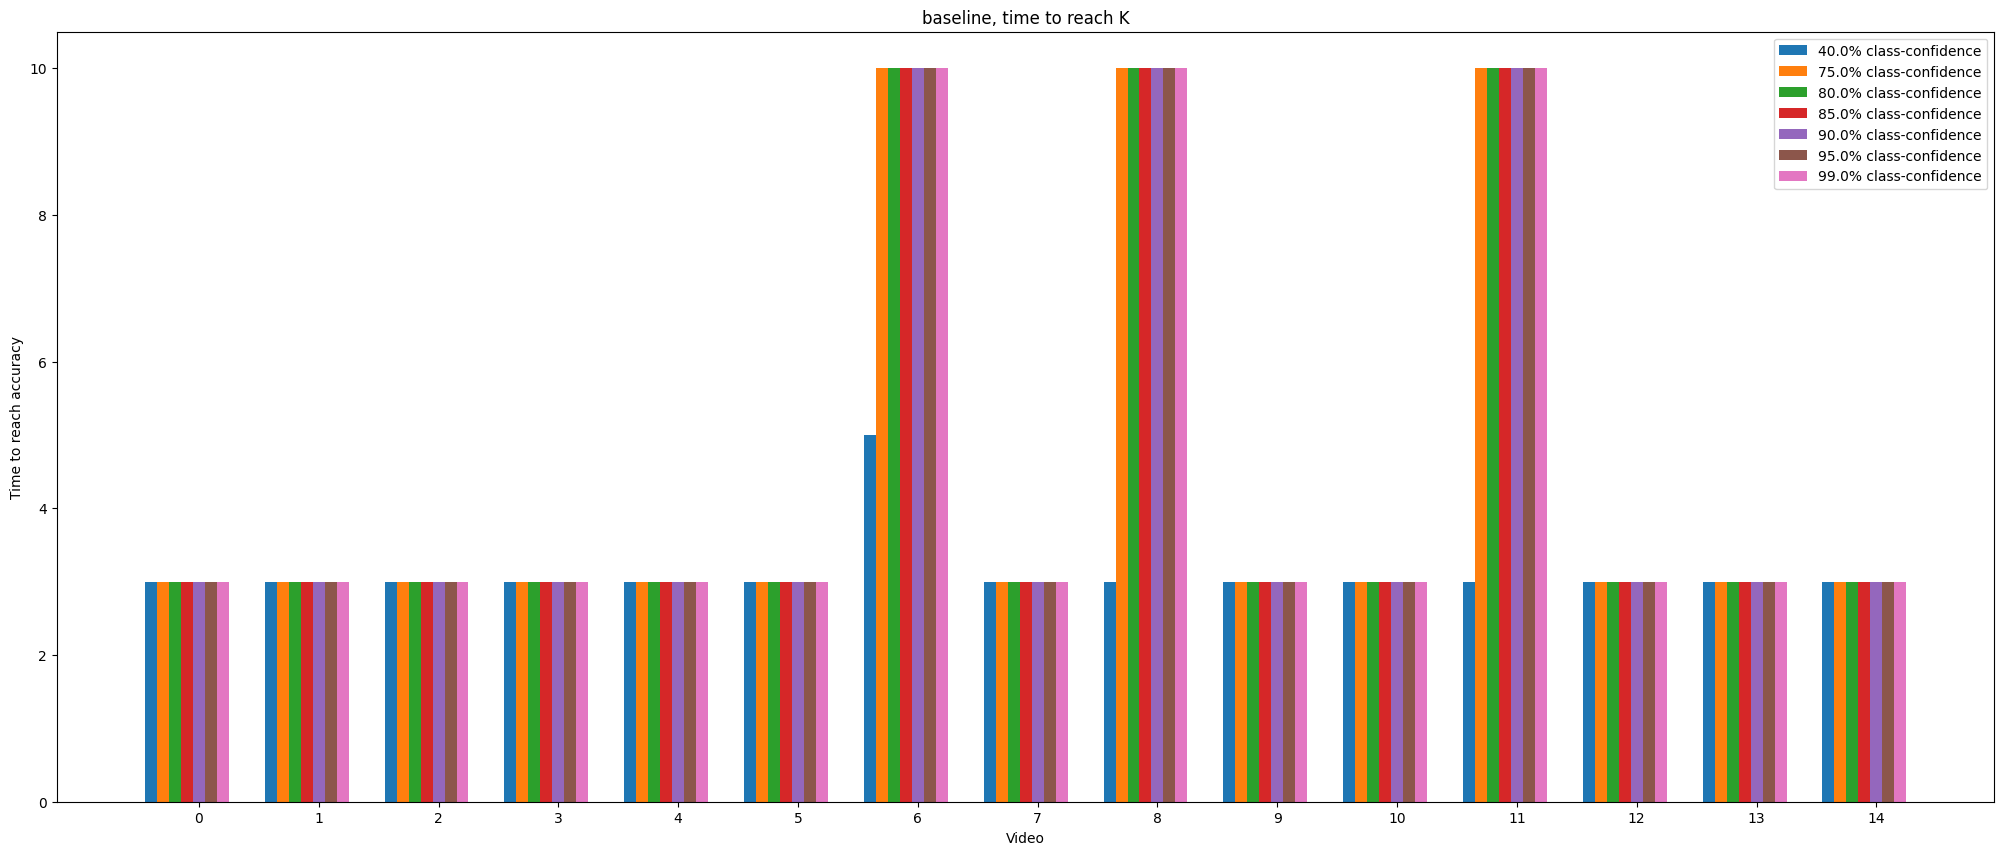

In [27]:
# Imposta la larghezza delle barre verticali del grafico
bar_width = 0.1

# Crea l'asse delle x in base al numero di elementi video presenti nel dataset
x = np.arange(len(real_video_classes))
my_xticks = real_video_classes
# Inizializza la figura con una dimensione orizzontale molto ampia per facilitare la lettura
fig, ax = plt.subplots(figsize=(25, 10))

# Disegna le barre per rappresentare il tempo necessario a raggiungere ciascuna soglia di accuratezza K
for k in range(0, len(classification_confidence_list)):
  ax.bar(x + (k * bar_width), times_baseline[k], width=bar_width)
# Imposta etichette per gli assi e titolo del grafico
ax.set(xlabel='Video', ylabel='Time to reach accuracy', title='baseline, time to reach K')
ax.set_xticks(x + bar_width * 4)
ax.set_xticklabels([counter for counter in range(0, len(real_video_classes))])
# Aggiunge la legenda per mappare i colori alle percentuali di confidenza
ax.legend(percents)

# Salva l'immagine nella cartella plots
plt.savefig(f"{plot_directory}/{times_plot_name}_{cc_plot_name}_{per_video_plot_name}.png")
# Mostra a schermo il grafico finale
plt.show()

## MCS

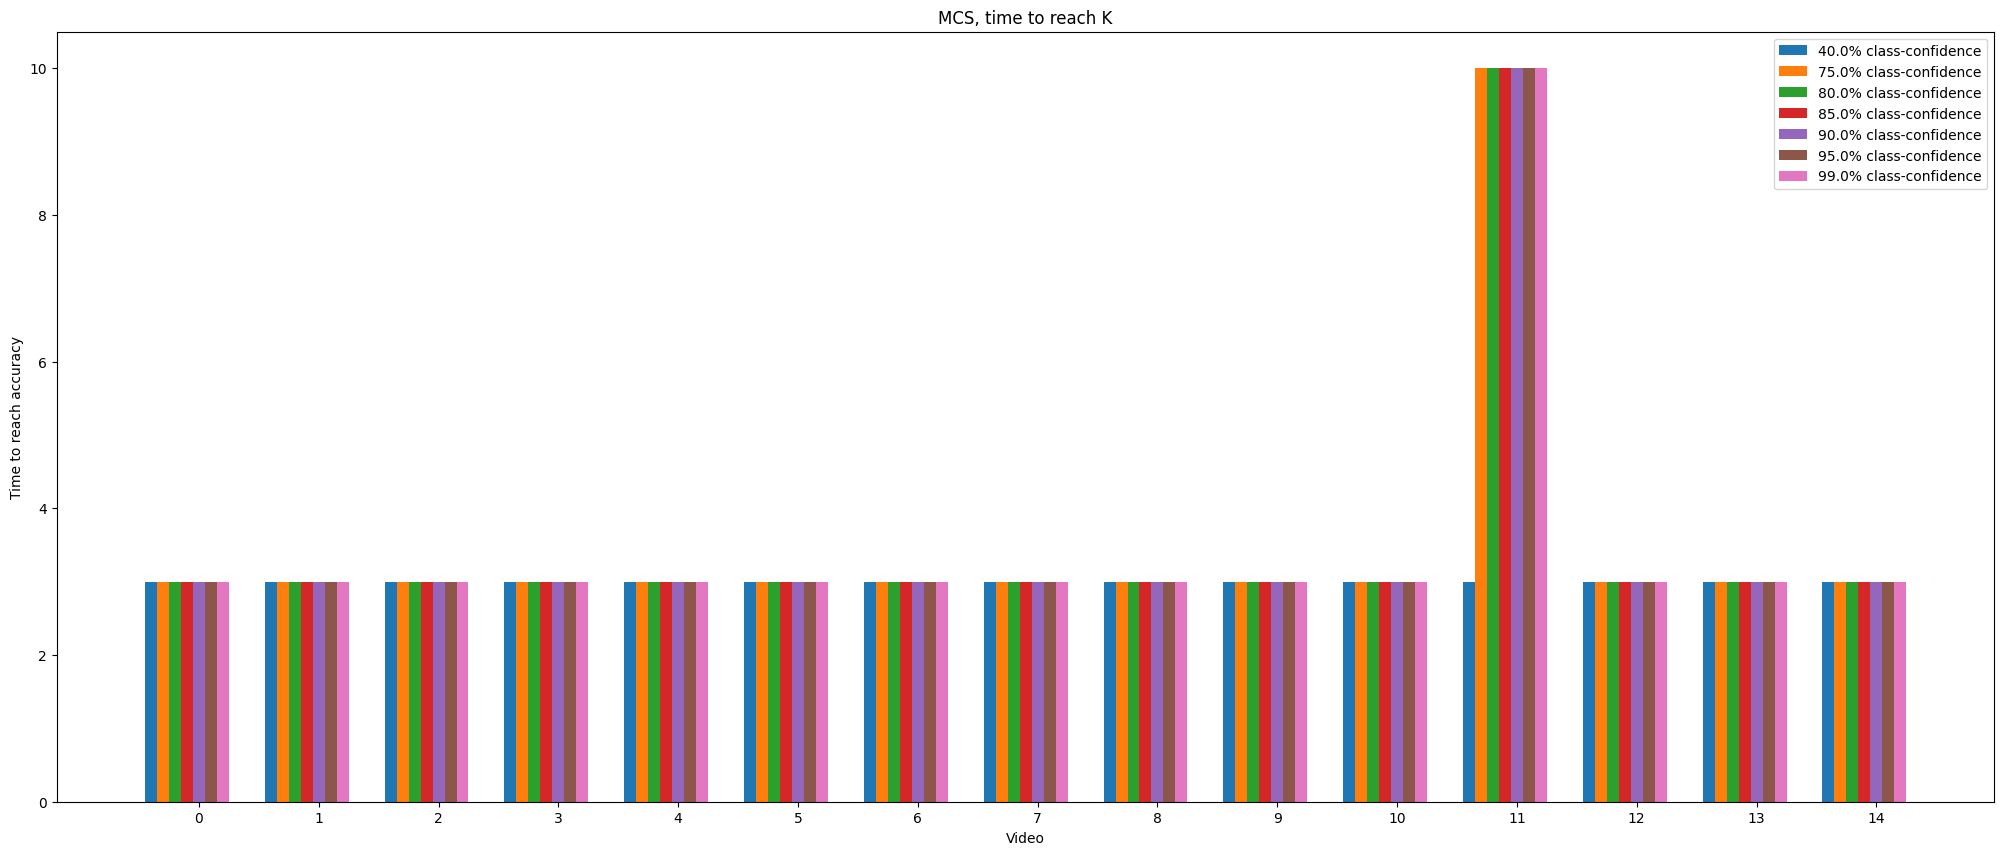

In [28]:
# Imposta lo spessore delle barre verticali
bar_width = 0.1

# Genera la sequenza di indici per i video sull'asse X
x = np.arange(len(real_video_classes))
my_xticks = real_video_classes
fig, ax = plt.subplots(figsize=(25, 10))

# Grafica i tempi di raggiungimento della confidenza per l'euristica MCS
for k in range(0, len(classification_confidence_list)):
  ax.bar(x + (k * bar_width), times_MCS[k], width=bar_width)
ax.set(xlabel='Video', ylabel='Time to reach accuracy', title='MCS, time to reach K')
ax.set_xticks(x + bar_width * 4)
ax.set_xticklabels([counter for counter in range(0, len(real_video_classes))])
ax.legend(percents)

# Salva il plot su file PNG
plt.savefig(f"{plot_directory}/{times_plot_name}_{mcs_plot_name}_{per_video_plot_name}.png")
plt.show()

## MCSwT

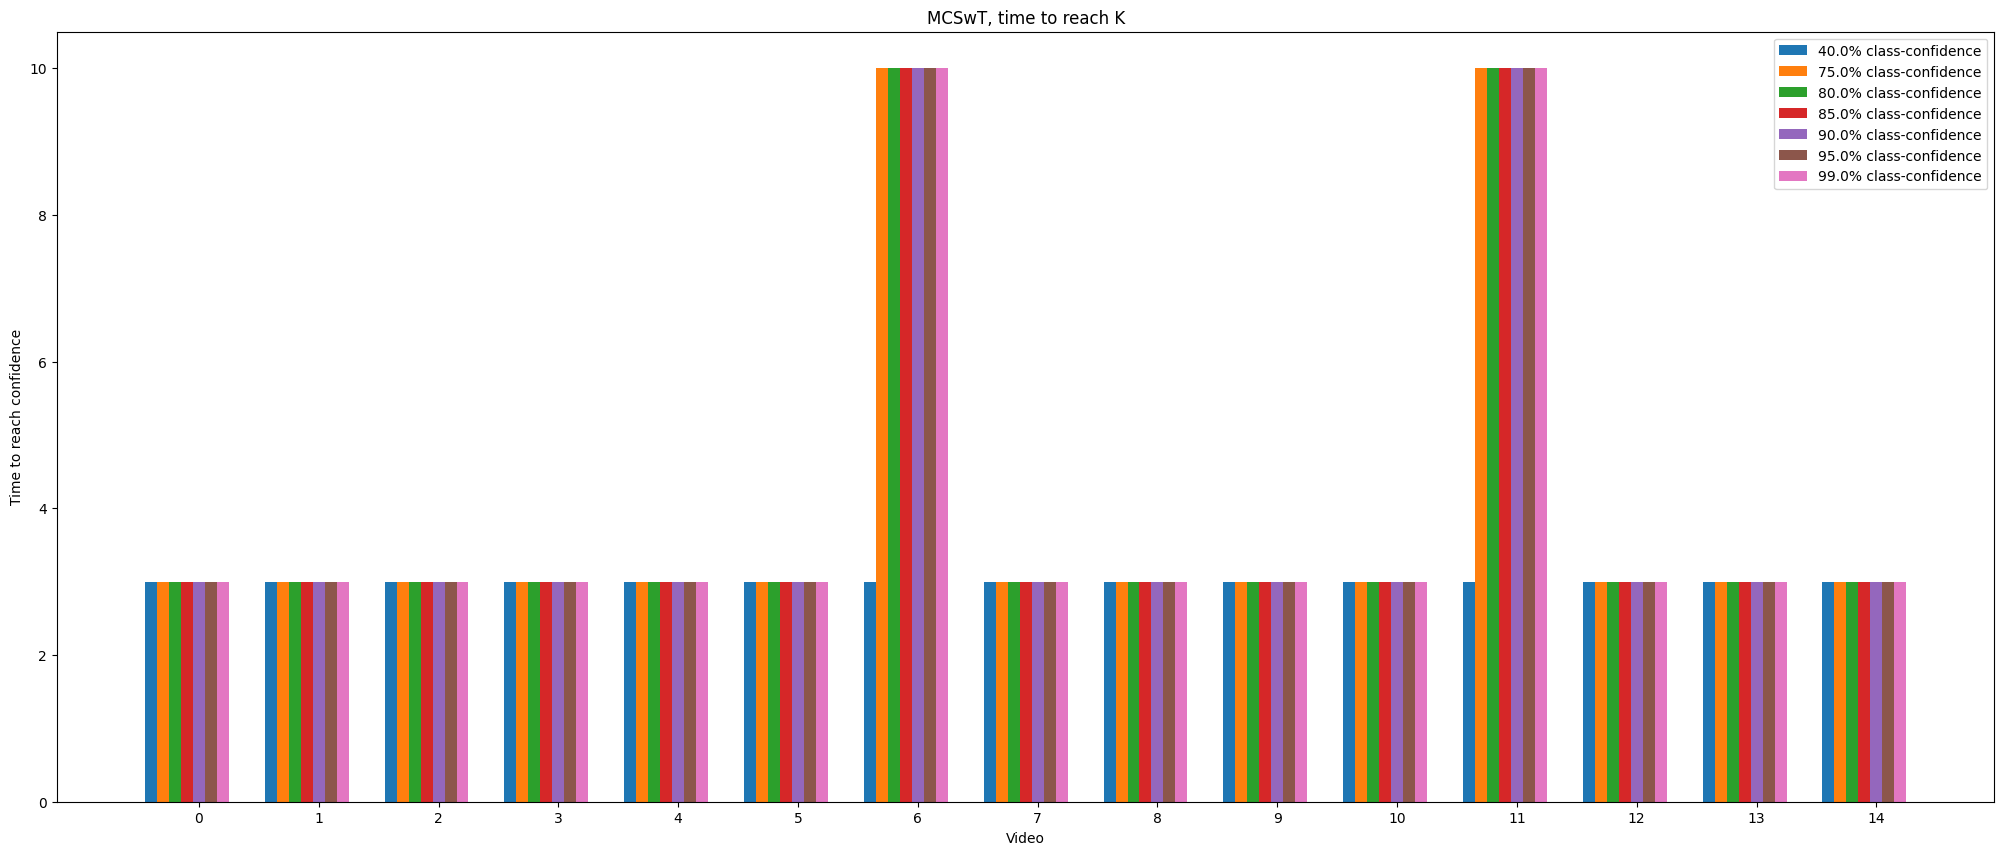

In [29]:
# Imposta lo spessore delle singole barre
bar_width = 0.1

# Costruisce la sequenza di indici numerici dei video
x = np.arange(len(real_video_classes))
my_xticks = real_video_classes
fig, ax = plt.subplots(figsize=(25, 10))

# Plotta le prestazioni temporali per l'euristica MCS con soglia di attivazione (MCSwT)
for k in range(0, len(classification_confidence_list)):
  ax.bar(x + (k * bar_width), times_MCSwT[k], width=bar_width)
ax.set(xlabel='Video', ylabel='Time to reach confidence', title='MCSwT, time to reach K')
ax.set_xticks(x + bar_width * 4)
ax.set_xticklabels([counter for counter in range(0, len(real_video_classes))])
ax.legend(percents)

# Esporta e salva il grafico su disco
plt.savefig(f"{plot_directory}/{times_plot_name}_{MCSwT_plot_name}_{per_video_plot_name}.png")
plt.show()

# Comparison of Means

## Facciamo la media di tutti i tempi di attivazione degli $n$ video

In [30]:
# Importa la funzione mean dal modulo statistics per il calcolo della media aritmetica
from statistics import mean

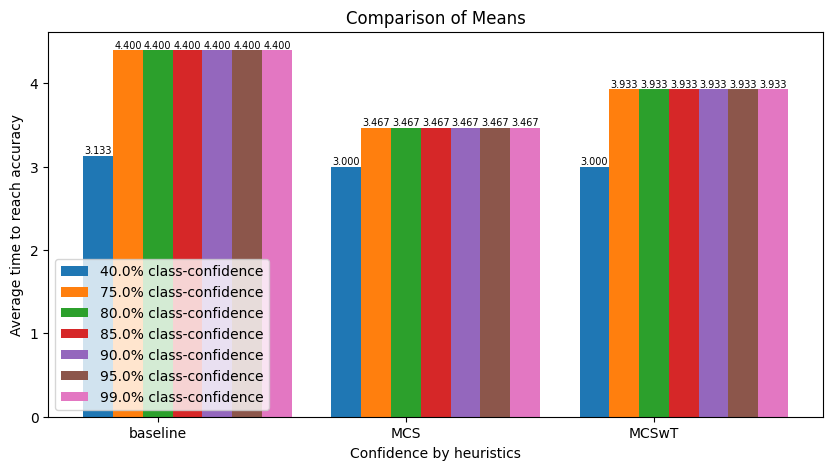

In [31]:
# Larghezza delle barre per il grafico comparativo delle medie
bar_width = 0.12

# Inizializzazione della figura
x = np.arange(len(heuristics))
my_xticks = real_video_classes
fig, ax = plt.subplots(figsize=(10, 5))

# Inizializza gli array per accumulare le medie dei tempi per ogni soglia K
times_cc_array_of_means = np.empty(0)
times_MCS_array_of_means = np.empty(0)
times_MCSwT_array_of_means = np.empty(0)

# Array per memorizzare la varianza dei tempi
variances_cc_array = []
variances_MCS_array = []
variances_MCSwT_array = []

# Calcola le medie e le varianze dei tempi di attivazione per ogni valore K della lista di confidenza
for k in range(0, len(classification_confidence_list)):
  times_baseline_mean = 0
  times_MCS_mean = 0
  times_MCSwT_mean = 0
  counter_baseline_mean = 0
  counter_MCS_mean = 0
  counter_MCSwT_mean = 0
  empty_column = False

  for j in range(0, n):
    times_baseline_mean += times_baseline[k][j]
    times_MCS_mean += times_MCS[k][j]
    times_MCSwT_mean += times_MCSwT[k][j]

  times_baseline_mean /= n
  times_MCS_mean /= n
  times_MCSwT_mean /= n

  times_cc_array_of_means = np.append(times_cc_array_of_means, times_baseline_mean)
  times_MCS_array_of_means = np.append(times_MCS_array_of_means, times_MCS_mean)
  times_MCSwT_array_of_means = np.append(times_MCSwT_array_of_means, times_MCSwT_mean)

  # Calcola le varianze dei tempi
  variance_cc = np.var(times_baseline[k])
  variance_MCS = np.var(times_MCS[k])
  variance_MCSwT = np.var(times_MCSwT[k])

  # Salva le varianze calcolate
  variances_cc_array.append(variance_cc)
  variances_MCS_array.append(variance_MCS)
  variances_MCSwT_array.append(variance_MCSwT)

# Rimodella gli array in vettori colonna prima del concatenamento
times_cc_array_of_means = times_cc_array_of_means.reshape((len(classification_confidence_list), 1))
times_MCS_array_of_means = times_MCS_array_of_means.reshape((len(classification_confidence_list), 1))
times_MCSwT_array_of_means = times_MCSwT_array_of_means.reshape((len(classification_confidence_list), 1))
data = np.stack([times_cc_array_of_means, times_MCS_array_of_means, times_MCSwT_array_of_means]).reshape((len(heuristics), len(classification_confidence_list)))
data = data.transpose()

# Disegna le barre e aggiunge le etichette con i valori precisi dei tempi medi sopra ciascuna barra
for k in range(0, len(classification_confidence_list)):
  bar_container = ax.bar(x + (k * bar_width), data[k], width=bar_width)
  ax.bar_label(bar_container, fmt='{:,.3f}', fontsize=7)
ax.set(xlabel='Confidence by heuristics', ylabel='Average time to reach accuracy', title='Comparison of Means')
ax.legend(percents, loc='lower left')
ax.set_xticks(x + bar_width * 2)
ax.set_xticklabels([heuristic for heuristic in heuristics])

# Salva il grafico e lo mostra
plt.savefig(f"{plot_directory}/{times_plot_name}_{avg_plot_name}.png")
plt.show()

## Boxplot dei tempi di attivazione
Nei grafici a seguire verrano creati tanti boxplot quante sono le soglie attivazione $K$ (quindi se `classification_confidence_list=[0.5, 0.7, 0.9]` allora verrano creati 3 boxplot) in modo tale da studiare la distribuzione dei tempi per ogni soglia $K$.

In [32]:
# Inizializza le liste vuote destinate a memorizzare i tempi per la visualizzazione tramite Boxplot
times_baseline_list = []
times_MCS_list = []
times_MCSwT_list = []

# Inizializza le liste destinate a contenere i tempi totali aggregati per ciascun video
all_times_baseline_list = []
all_times_MCS_list = []
all_times_MCSwT_list = []

# Popola le liste convertendo gli array NumPy in liste standard Python e aggregando i valori
for k in range(0, len(classification_confidence_list)):
  times_baseline_list.append(times_baseline[k].tolist())
  times_MCS_list.append(times_MCS[k].tolist())
  times_MCSwT_list.append(times_MCSwT[k].tolist())
  for video_index in range(0, n):
    all_times_baseline_list.append(times_baseline[k][video_index])
    all_times_MCS_list.append(times_MCS[k][video_index])
    all_times_MCSwT_list.append(times_MCSwT[k][video_index])

## baseline (baseline)

In [33]:
# Stampa le liste dei tempi registrati per l'euristica di baseline per ispezionare i dati numerici
for i in range(0, len(classification_confidence_list)):
  print(times_baseline_list[i])

[3.0, 3.0, 3.0, 3.0, 3.0, 3.0, 5.0, 3.0, 3.0, 3.0, 3.0, 3.0, 3.0, 3.0, 3.0]
[3.0, 3.0, 3.0, 3.0, 3.0, 3.0, 10.0, 3.0, 10.0, 3.0, 3.0, 10.0, 3.0, 3.0, 3.0]
[3.0, 3.0, 3.0, 3.0, 3.0, 3.0, 10.0, 3.0, 10.0, 3.0, 3.0, 10.0, 3.0, 3.0, 3.0]
[3.0, 3.0, 3.0, 3.0, 3.0, 3.0, 10.0, 3.0, 10.0, 3.0, 3.0, 10.0, 3.0, 3.0, 3.0]
[3.0, 3.0, 3.0, 3.0, 3.0, 3.0, 10.0, 3.0, 10.0, 3.0, 3.0, 10.0, 3.0, 3.0, 3.0]
[3.0, 3.0, 3.0, 3.0, 3.0, 3.0, 10.0, 3.0, 10.0, 3.0, 3.0, 10.0, 3.0, 3.0, 3.0]
[3.0, 3.0, 3.0, 3.0, 3.0, 3.0, 10.0, 3.0, 10.0, 3.0, 3.0, 10.0, 3.0, 3.0, 3.0]


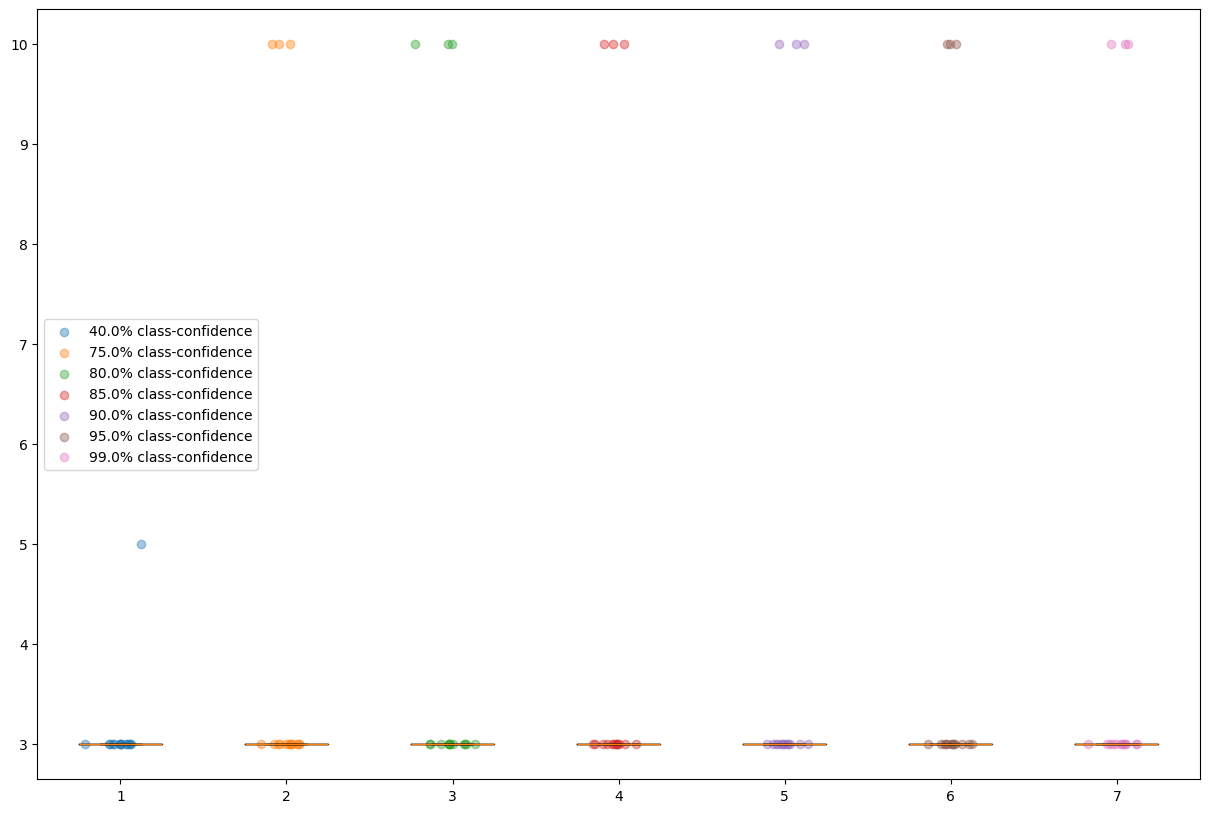

In [34]:
# Creazione di una figura per i boxplot verticali per l'euristica baseline
fig, ax = plt.subplots(figsize=(15, 10))

# Creazione dei boxplot verticali escludendo gli outlier per una visualizzazione più pulita
bp = ax.boxplot(times_baseline_list, vert=True, showfliers=False)
points = []
# Sovrappone i singoli punti di dati reali con un leggero rumore sull'asse X per evitare sovrapposizioni (jitter)
for i in range(0, len(classification_confidence_list)):
  y = times_baseline_list[i]
  x = np.random.normal(1+i, 0.07, size=len(y))
  points.append(plt.scatter(x, y, alpha=0.4))
ax.legend(points, percents, loc='center left')

# Salva il grafico e lo mostra a schermo
plt.savefig(f"{plot_directory}/{times_plot_name}_{boxplot_plot_name}_{cc_plot_name}_{per_acc_plot_name}.png")
plt.show()

## MCS

In [35]:
# Stampa i valori dei tempi registrati per l'euristica MCS per ciascun livello di confidenza
for i in range(0, len(classification_confidence_list)):
  print(times_MCS_list[i])

[3.0, 3.0, 3.0, 3.0, 3.0, 3.0, 3.0, 3.0, 3.0, 3.0, 3.0, 3.0, 3.0, 3.0, 3.0]
[3.0, 3.0, 3.0, 3.0, 3.0, 3.0, 3.0, 3.0, 3.0, 3.0, 3.0, 10.0, 3.0, 3.0, 3.0]
[3.0, 3.0, 3.0, 3.0, 3.0, 3.0, 3.0, 3.0, 3.0, 3.0, 3.0, 10.0, 3.0, 3.0, 3.0]
[3.0, 3.0, 3.0, 3.0, 3.0, 3.0, 3.0, 3.0, 3.0, 3.0, 3.0, 10.0, 3.0, 3.0, 3.0]
[3.0, 3.0, 3.0, 3.0, 3.0, 3.0, 3.0, 3.0, 3.0, 3.0, 3.0, 10.0, 3.0, 3.0, 3.0]
[3.0, 3.0, 3.0, 3.0, 3.0, 3.0, 3.0, 3.0, 3.0, 3.0, 3.0, 10.0, 3.0, 3.0, 3.0]
[3.0, 3.0, 3.0, 3.0, 3.0, 3.0, 3.0, 3.0, 3.0, 3.0, 3.0, 10.0, 3.0, 3.0, 3.0]


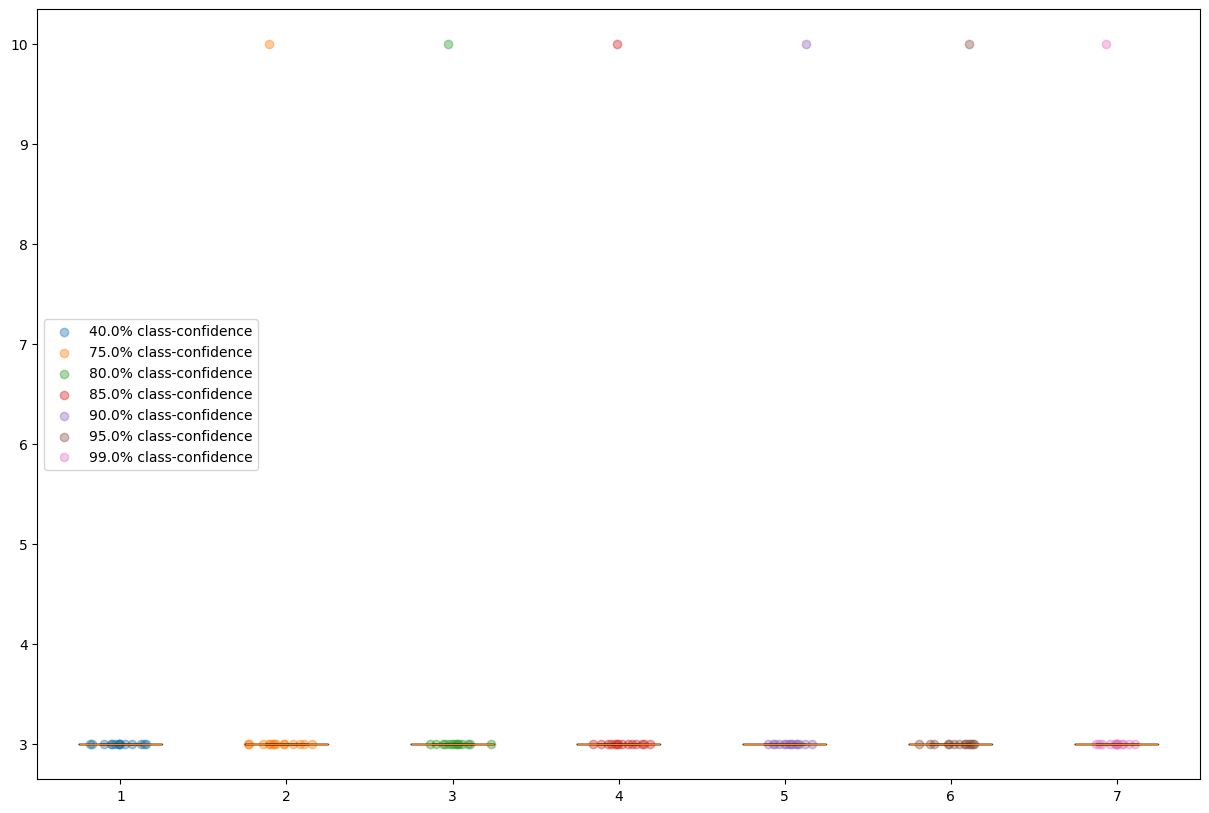

In [36]:
# Creazione di una figura per i boxplot verticali dell'euristica MCS
fig, ax = plt.subplots(figsize=(15, 10))

# Creazione dei boxplot escludendo gli outlier visivi
bp = ax.boxplot(times_MCS_list, vert=True, showfliers=False)
points = []
# Aggiunge i punti scatter con effetto jitter per evidenziare la densità dei dati
for i in range(0, len(classification_confidence_list)):
  y = times_MCS_list[i]
  x = np.random.normal(1+i, 0.1, size=len(y))
  points.append(plt.scatter(x, y, alpha=0.4))
ax.legend(points, percents, loc='center left')

# Salva il file e visualizza
plt.savefig(f"{plot_directory}/{times_plot_name}_{boxplot_plot_name}_{mcs_plot_name}_{per_acc_plot_name}.png")
plt.show()

## MCSwT

In [37]:
# Stampa i tempi dell'euristica MCSwT e calcola la somma totale per l'ultimo livello di confidenza
for i in range(0, len(classification_confidence_list)):
  print(times_MCSwT_list[i])
  if i == len(classification_confidence_list) - 1:
    print(np.sum(times_MCSwT_list[i]))

[3.0, 3.0, 3.0, 3.0, 3.0, 3.0, 3.0, 3.0, 3.0, 3.0, 3.0, 3.0, 3.0, 3.0, 3.0]
[3.0, 3.0, 3.0, 3.0, 3.0, 3.0, 10.0, 3.0, 3.0, 3.0, 3.0, 10.0, 3.0, 3.0, 3.0]
[3.0, 3.0, 3.0, 3.0, 3.0, 3.0, 10.0, 3.0, 3.0, 3.0, 3.0, 10.0, 3.0, 3.0, 3.0]
[3.0, 3.0, 3.0, 3.0, 3.0, 3.0, 10.0, 3.0, 3.0, 3.0, 3.0, 10.0, 3.0, 3.0, 3.0]
[3.0, 3.0, 3.0, 3.0, 3.0, 3.0, 10.0, 3.0, 3.0, 3.0, 3.0, 10.0, 3.0, 3.0, 3.0]
[3.0, 3.0, 3.0, 3.0, 3.0, 3.0, 10.0, 3.0, 3.0, 3.0, 3.0, 10.0, 3.0, 3.0, 3.0]
[3.0, 3.0, 3.0, 3.0, 3.0, 3.0, 10.0, 3.0, 3.0, 3.0, 3.0, 10.0, 3.0, 3.0, 3.0]
59.0


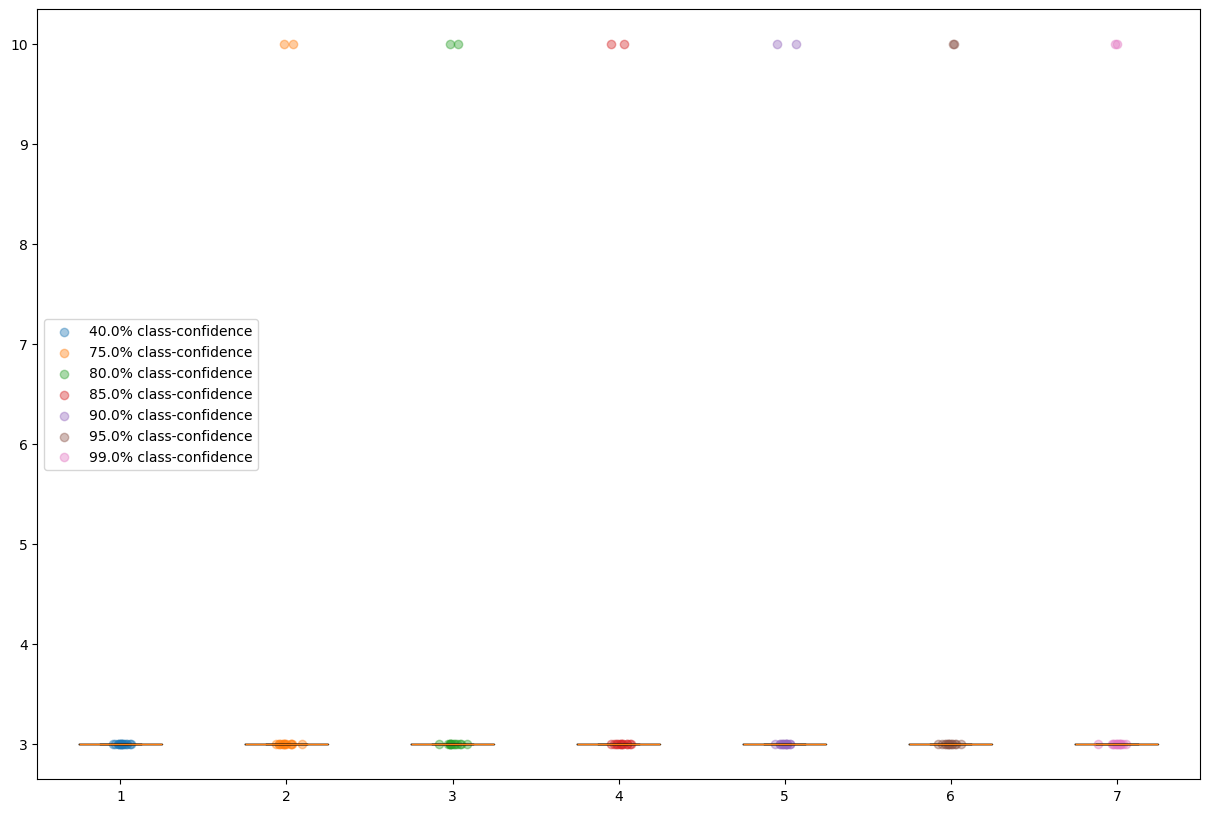

In [38]:
# Creazione di una figura per i boxplot verticali per l'euristica MCSwT
fig, ax = plt.subplots(figsize=(15, 10))

# Disegna i boxplot verticali escludendo gli outlier estremi
bp = ax.boxplot(times_MCSwT_list, vert=True, showfliers=False)
points = []
# Genera i punti sovrapposti con rumore casuale ristretto (0.04) per evitare sovrapposizioni
for i in range(0, len(classification_confidence_list)):
  y = times_MCSwT_list[i]
  x = np.random.normal(1+i, 0.04, size=len(y))
  points.append(plt.scatter(x, y, alpha=0.4))
ax.legend(points, percents, loc='center left')

# Salva e mostra il grafico
plt.savefig(f"{plot_directory}/{times_plot_name}_{boxplot_plot_name}_{MCSwT_plot_name}_{per_acc_plot_name}.png")
plt.show()

## Confronto tra boxplot: tempi aggregati
Il seguente grafico considera la distribuzione dei tempi di attivazione aggregati per euristica (quindi non più per soglia di attivazione $K$).
In questo modo possiamo visualizzare la distribuzione dei tempi in base alle euristiche utilizzate.

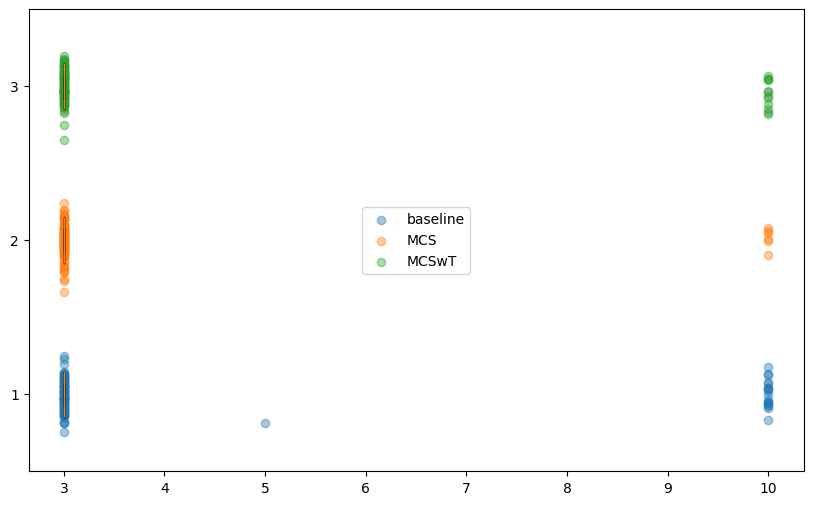

In [39]:
# Prepara i dati aggregati dei tempi per tutte le tre euristiche messe a confronto
data = [all_times_baseline_list, all_times_MCS_list, all_times_MCSwT_list]
fig, ax = plt.subplots(figsize=(10, 6))
# Creazione dei boxplot orizzontali per una lettura facilitata
bp = ax.boxplot(data, showfliers=False, vert=False)
points = []
# Disegna i singoli punti reali associati a ciascuna euristica
for i in range(0, len(heuristics)):
  x = data[i]
  y = np.random.normal(i+1, 0.1, size=len(x))
  points.append(plt.scatter(x, y, alpha=0.4))
ax.legend(points, heuristics, loc='center')

# Salva e visualizza il grafico di confronto complessivo delle distribuzioni dei tempi
plt.savefig(f"{plot_directory}/{times_plot_name}_{boxplot_plot_name}.png")
plt.show()

## Numero di video che non hanno raggiunto l'accuracy
Dai grafici precedenti sembrerebbe che tutti i video abbiamo raggiunto tutte le accuracy che sono state analizzate: non è così. \\
Il problema è che alcune volte il meccanismo di registrazione del tempo impiegato al raggiungimento di una determinata soglia di accuracy non riesce ad attivarsi proprio perchè l'accuracy non è abbastanza.

Per questo abbiamo deciso in fase di sviluppo di aggiungere una costante (la durata del video in questione, $\text{sec}$) qualora vi fossero video che non raggiungessero tale accuracy.

Nel grafico a seguire catturiamo quello che non siamo riusciti a catturare: quanti video non hanno raggiunto l'accuracy.

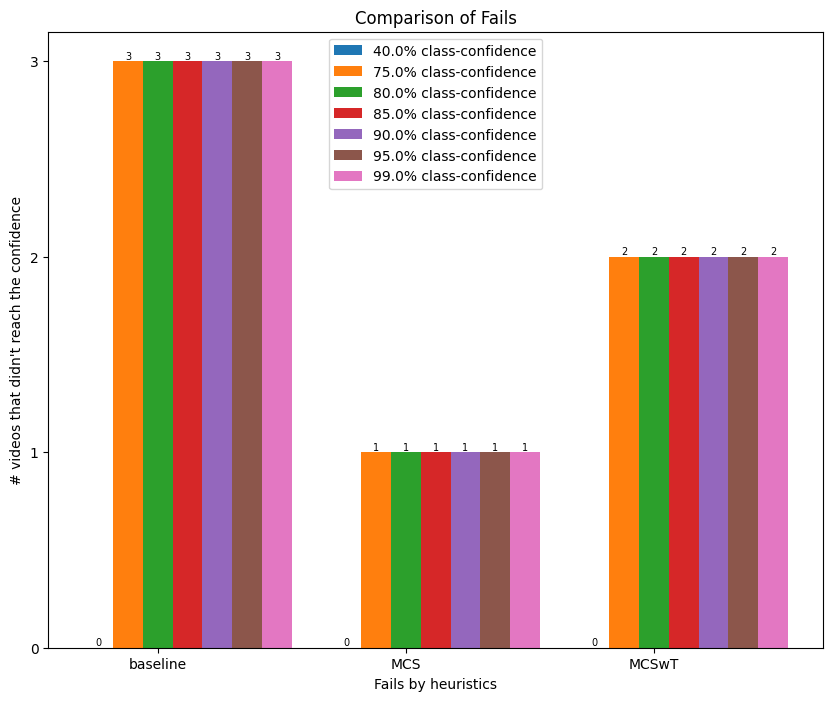

In [40]:
# Genera l'asse delle ascisse in base al numero di euristiche in esame
x = np.arange(len(heuristics))

fig, ax = plt.subplots(figsize=(10, 8))
# Convertiamo i dizionari dei fallimenti in array NumPy rimodellandoli per l'impilamento
fails_baseline_array = np.array(list(fails_baseline.values())).reshape(len(classification_confidence_list), 1)
fails_MCS_array = np.array(list(fails_MCS.values())).reshape(len(classification_confidence_list), 1)
fails_MCSwT_array = np.array(list(fails_MCSwT.values())).reshape(len(classification_confidence_list), 1)
data = np.stack([fails_baseline_array, fails_MCS_array, fails_MCSwT_array]).reshape((len(heuristics), len(classification_confidence_list)))
data = data.transpose()

# Disegna le barre dei fallimenti e posiziona le etichette di testo con i conteggi interi esatti sopra ognuna di esse
for k in range(0, len(classification_confidence_list)):
  bar_container = ax.bar(x + (k * bar_width), data[k], width=bar_width)
  ax.bar_label(bar_container, fmt='{:,.0f}', fontsize=7)
ax.set(xlabel='Fails by heuristics', ylabel="# videos that didn't reach the confidence", title='Comparison of Fails')
ax.legend(percents, loc='upper center')
ax.set_xticks(x + bar_width * 2)
ax.set_xticklabels([heuristic for heuristic in heuristics])
# Rimuovi i tick sull'asse y e mostra solo valori interi
ax.yaxis.set_major_locator(plt.MaxNLocator(integer=True))

# Salva e mostra il grafico finale dei fallimenti
plt.savefig(f"{plot_directory}/{times_plot_name}_accuracy_{fails_plot_name}.png")
plt.show()

# Grafico a barre (classificazioni frame singoli)
Nel grafico a seguire verranno messi sull'asse delle $x$ le classi (reali) $c$ dei video (e.g. $\text{passenger}$) e per ogni video vengono indicati con diversi colori il numero di frame classificati ($\text{rosso}=\text{driver}$, $\text{verde}=\text{passenger}$, $\text{blu}=\text{none}$)

In [41]:
# Definizione dell'array contenente le tre categorie di classificazione possibili per i singoli frame
classes = ["driver", "passenger", "none"]

## baseline (baseline)

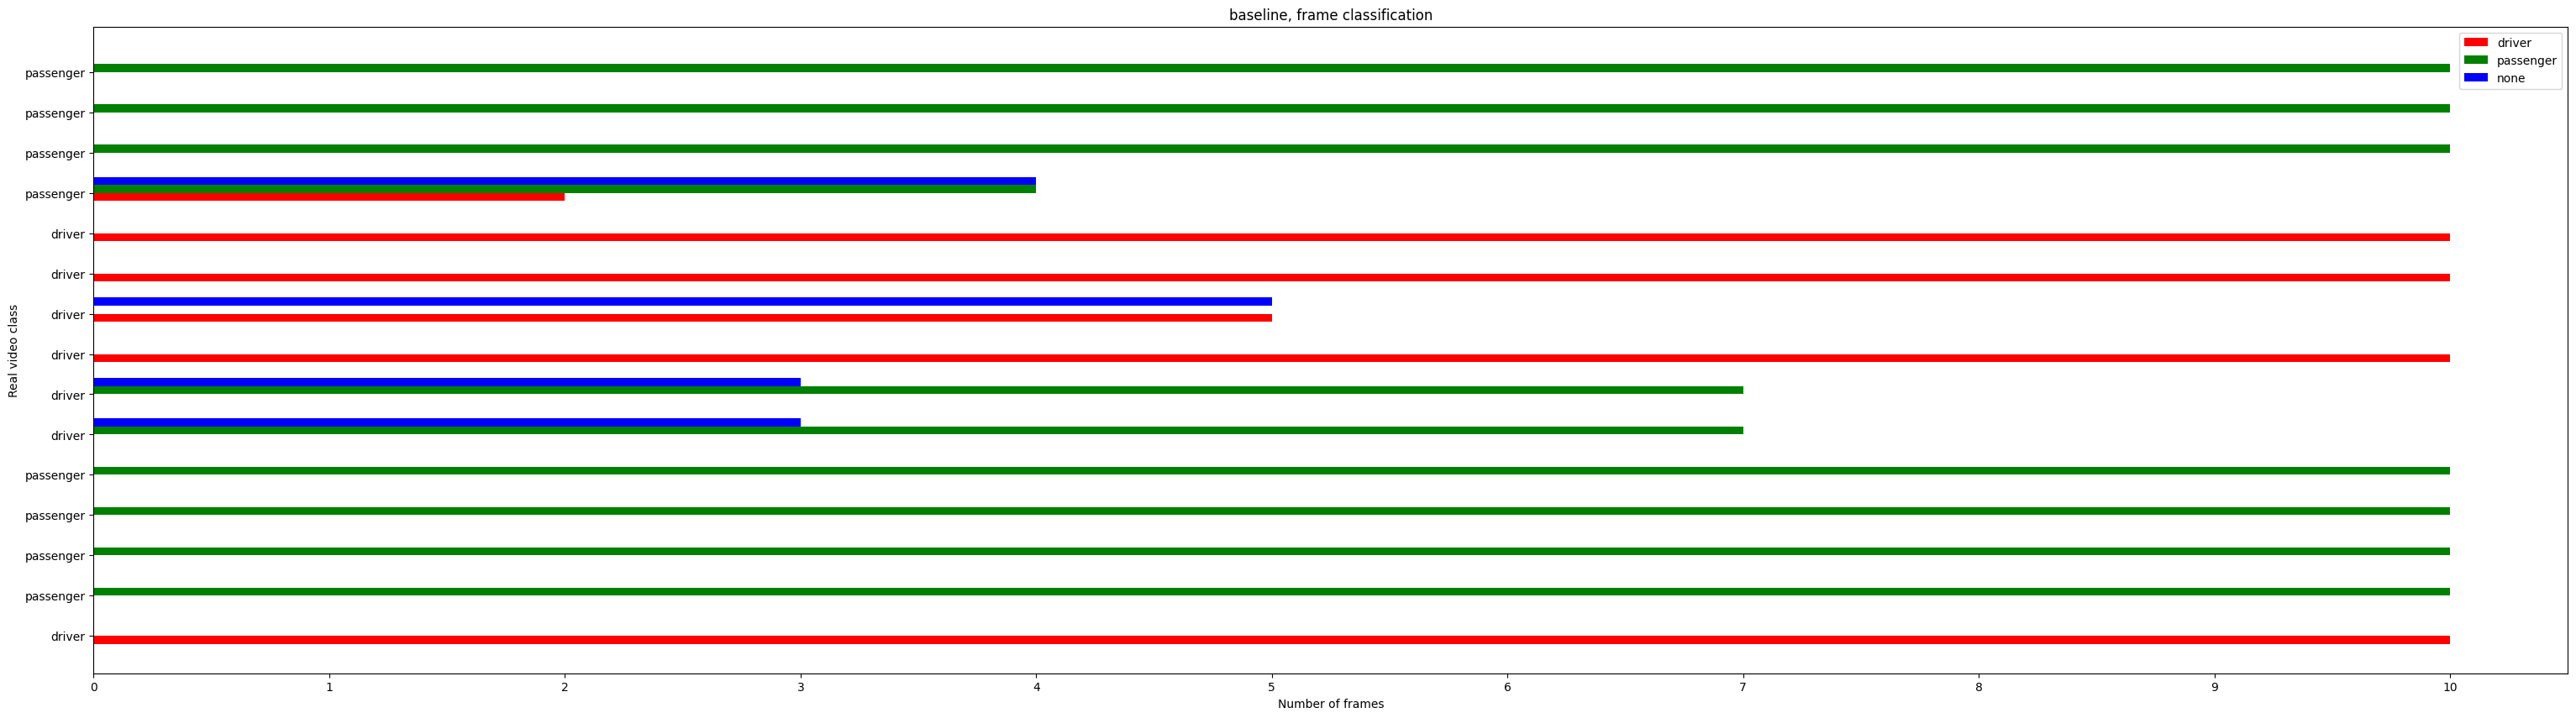

In [42]:
# Altezza di ciascuna barra orizzontale del grafico
bar_height = 0.2

# Costruisce gli indici per l'asse delle ordinate (corrispondenti ai video)
x = np.arange(len(real_video_classes))
my_xticks = real_video_classes
# Organizza l'array di predizioni rimodellandolo per contenere le sequenze di frame di ciascun video
y = baseline_predictions.reshape((n, fps * sec))

fig, ax = plt.subplots(figsize=(38, 10))
# Inizializza un DataFrame vuoto per accumulare i conteggi dei frame per ciascun video
big_df_baseline = pd.DataFrame(columns = classes)
for video_frame_predictions in y:
  my_array = np.array([
      np.count_nonzero(video_frame_predictions == "driver"),
      np.count_nonzero(video_frame_predictions == "passenger"),
      np.count_nonzero(video_frame_predictions == "none")
    ])
  df = pd.DataFrame([my_array], columns = classes)
  big_df_baseline = pd.concat([big_df_baseline, df])

# Rappresenta graficamente le barre orizzontali accostate per conducente (rosso), passeggero (verde) e nullo (blu)
ax.barh(x, big_df_baseline["driver"], height=bar_height, color='r')
ax.barh(x+bar_height, big_df_baseline["passenger"], height=bar_height, color='g')
ax.barh(x+2*bar_height, big_df_baseline['none'], height=bar_height, color='b')
ax.set_yticks(x + bar_height / 2)
ax.set_yticklabels(real_video_classes)
ax.set_xticks(np.arange(fps * sec + 1))
ax.set(xlabel='Number of frames', ylabel='Real video class', title='baseline, frame classification')
ax.legend(classes)

# Salva il plot orizzontale in formato PNG
plt.savefig(f"{plot_directory}/{classifications_plot_name}_{cc_plot_name}_{per_video_plot_name}.png")
plt.show()

<class 'numpy.ndarray'>


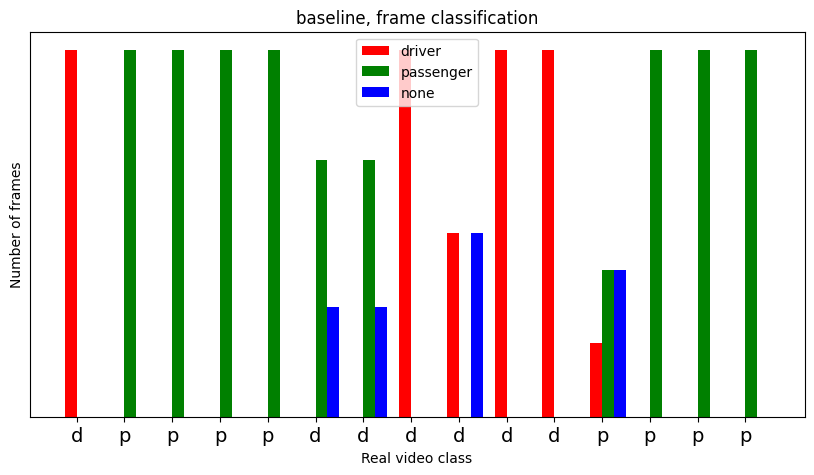

In [43]:
# Spessore delle barre verticali del grafico
bar_height = 0.25

# Crea l'asse X per rappresentare ciascun video in sequenza
y = np.arange(len(real_video_classes))
my_xticks = real_video_classes
# Rimodella l'array delle predizioni della baseline
x = baseline_predictions.reshape((n, fps * sec))

fig, ax = plt.subplots(figsize=(10, 5))
big_df_baseline = pd.DataFrame(columns = classes)
# Calcola e accumula i conteggi di frame per ogni classe all'interno di ciascun video
for video_frame_predictions in x:
  my_array = np.array([
      np.count_nonzero(video_frame_predictions == "driver"),
      np.count_nonzero(video_frame_predictions == "passenger"),
      np.count_nonzero(video_frame_predictions == "none")
    ])
  df = pd.DataFrame([my_array], columns = classes)
  big_df_baseline = pd.concat([big_df_baseline, df])

# Disegna le barre verticali per conducente, passeggero e indefinito
ax.bar(y, big_df_baseline["driver"], width=bar_height, color='r')
ax.bar(y+bar_height, big_df_baseline["passenger"], width=bar_height, color='g')
ax.bar(y+2*bar_height, big_df_baseline['none'], width=bar_height, color='b')
ax.set_xticks(y + bar_height / 2)
# Funzione anonima per prendere solo l'iniziale del nome della classe
f = lambda x: x[0]
my_func = np.vectorize(f)
print(type(real_video_classes))
ax.set_xticklabels(my_func(real_video_classes), fontsize=14)
ax.set_yticks([])
ax.set(ylabel='Number of frames', xlabel='Real video class', title='baseline, frame classification')
ax.legend(classes)

# Salva la versione del grafico con orientamento verticale
plt.savefig(f"{plot_directory}/{classifications_plot_name}_{cc_plot_name}_{per_video_plot_name}_horizontal.png")
plt.show()

## MCS

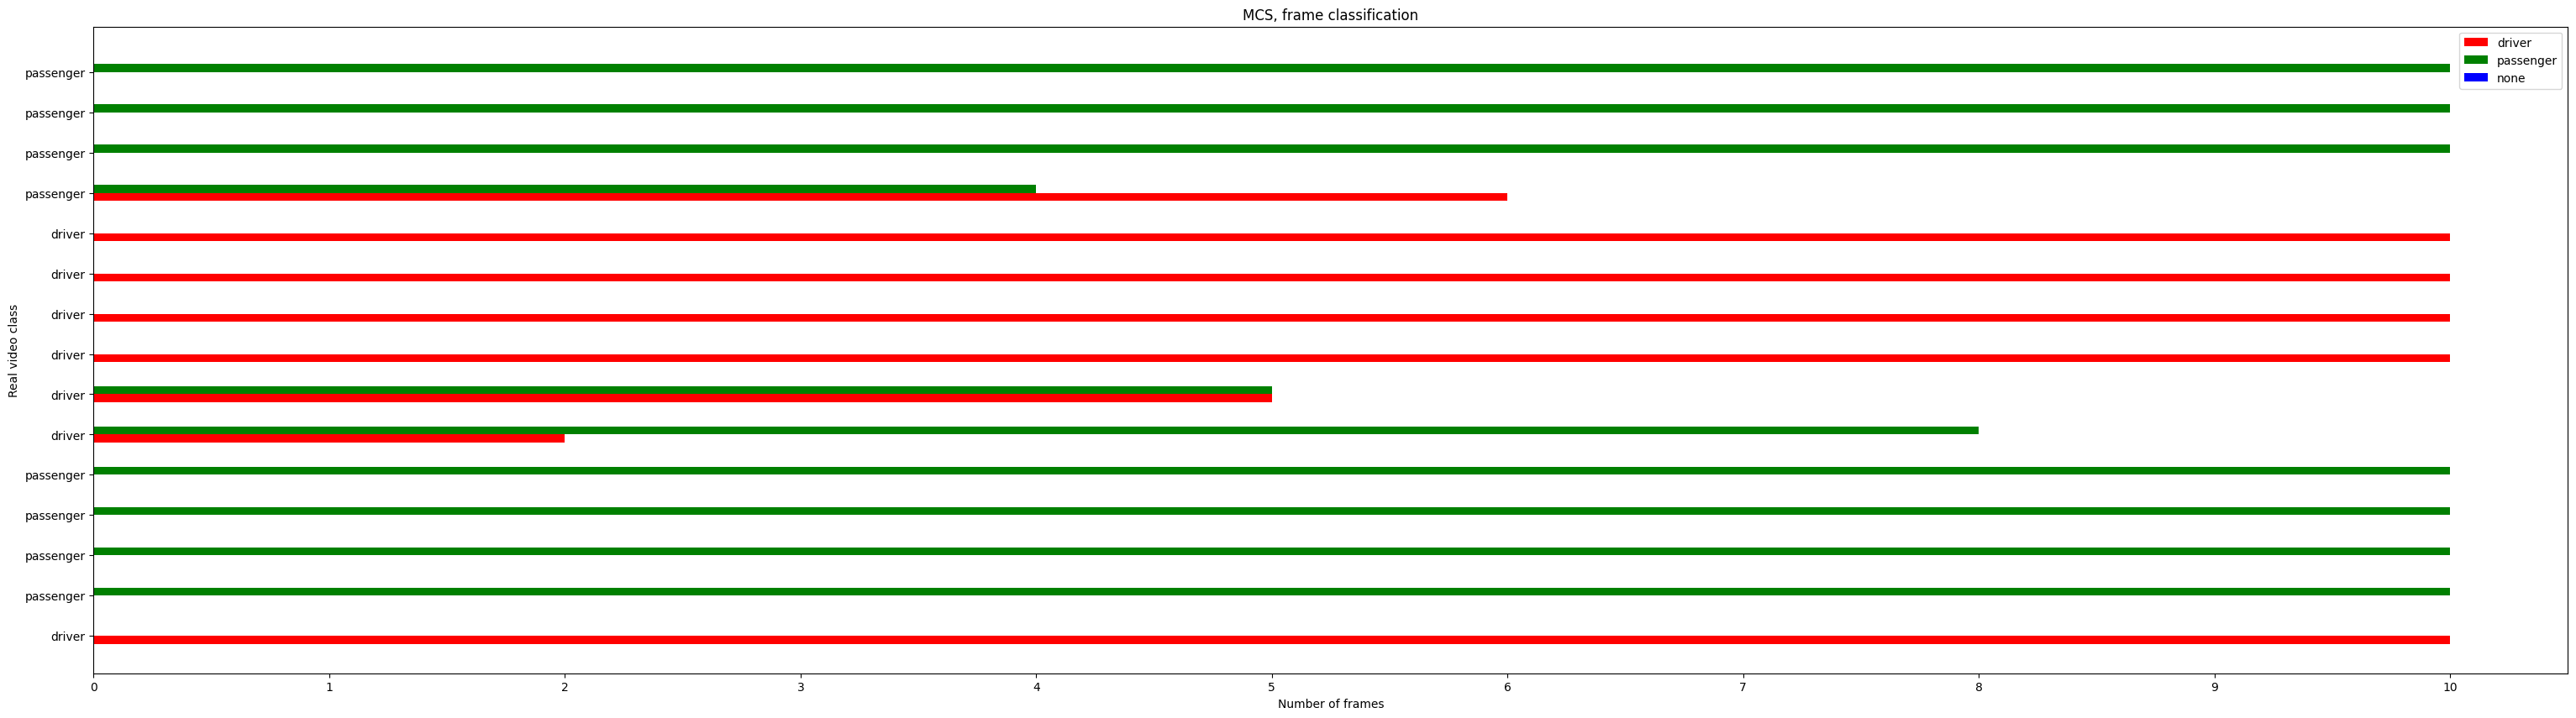

In [44]:
# Spessore delle barre orizzontali
bar_height = 0.2

# Costruisce l'asse Y per i video
x = np.arange(len(real_video_classes))
my_xticks = real_video_classes
# Rimodella l'array multidimensionale per le predizioni dell'algoritmo MCS
y = MCS_predictions.reshape((n, fps * sec))

fig, ax = plt.subplots(figsize=(38, 10))
big_df_MCS = pd.DataFrame(columns = classes)
# Calcola la ripartizione dei frame per conducente, passeggero e nullo su ogni video
for video_frame_predictions in y:
  my_array = np.array([
      np.count_nonzero(video_frame_predictions == "driver"),
      np.count_nonzero(video_frame_predictions == "passenger"),
      np.count_nonzero(video_frame_predictions == "none")
    ])
  df = pd.DataFrame([my_array], columns = classes)
  big_df_MCS = pd.concat([big_df_MCS, df])

# Rappresenta graficamente i conteggi tramite barre orizzontali
ax.barh(x, big_df_MCS["driver"], height=bar_height, color='r')
ax.barh(x+bar_height, big_df_MCS["passenger"], height=bar_height, color='g')
ax.barh(x+2*bar_height, big_df_MCS['none'], height=bar_height, color='b')
ax.set_yticks(x + bar_height / 2)
ax.set_yticklabels(real_video_classes)
ax.set_xticks(np.arange(fps * sec + 1))
ax.set(xlabel='Number of frames', ylabel='Real video class', title='MCS, frame classification')
ax.legend(classes)

# Salva il plot generato
plt.savefig(f"{plot_directory}/{classifications_plot_name}_{mcs_plot_name}_{per_video_plot_name}.png")
plt.show()

<class 'numpy.ndarray'>


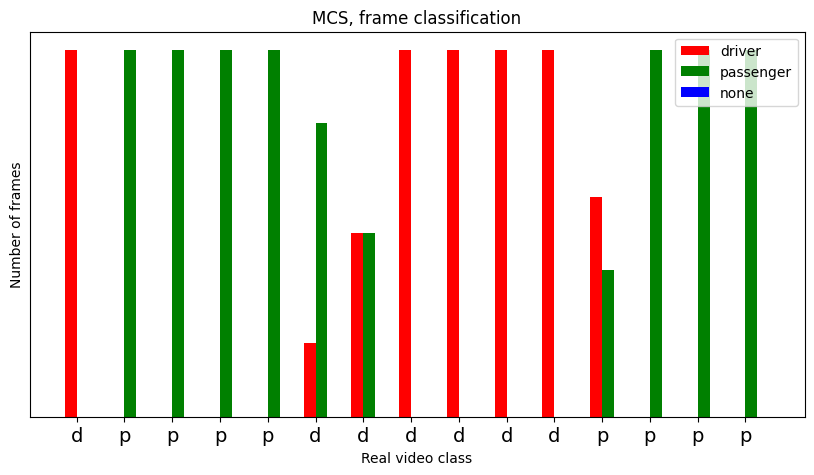

In [45]:
# Spessore standard delle barre verticali del plot
bar_height = 0.25

# Array degli indici dei video sull'asse delle ascisse
y = np.arange(len(real_video_classes))
my_xticks = real_video_classes
# Rimodella le predizioni MCS per la rappresentazione grafica
x = MCS_predictions.reshape((n, fps * sec))

fig, ax = plt.subplots(figsize=(10, 5))
big_df_MCS = pd.DataFrame(columns = classes)
# Esegue il conteggio delle categorie per ciascun video e popola il DataFrame finale
for video_frame_predictions in x:
  my_array = np.array([
      np.count_nonzero(video_frame_predictions == "driver"),
      np.count_nonzero(video_frame_predictions == "passenger"),
      np.count_nonzero(video_frame_predictions == "none")
    ])
  df = pd.DataFrame([my_array], columns = classes)
  big_df_MCS = pd.concat([big_df_MCS, df])

# Plotta le tre categorie di barre verticali per ciascun video
ax.bar(y, big_df_MCS["driver"], width=bar_height, color='r')
ax.bar(y+bar_height, big_df_MCS["passenger"], width=bar_height, color='g')
ax.bar(y+2*bar_height, big_df_MCS['none'], width=bar_height, color='b')
ax.set_xticks(y + bar_height / 2)
f = lambda x: x[0]
my_func = np.vectorize(f)
print(type(real_video_classes))
ax.set_xticklabels(my_func(real_video_classes), fontsize=14)
ax.set_yticks([])
ax.set(ylabel='Number of frames', xlabel='Real video class', title='MCS, frame classification')
ax.legend(classes)

# Salva e mostra il grafico a barre verticali
plt.savefig(f"{plot_directory}/{classifications_plot_name}_{mcs_plot_name}_{per_video_plot_name}_horizontal.png")
plt.show()

## MCSwT

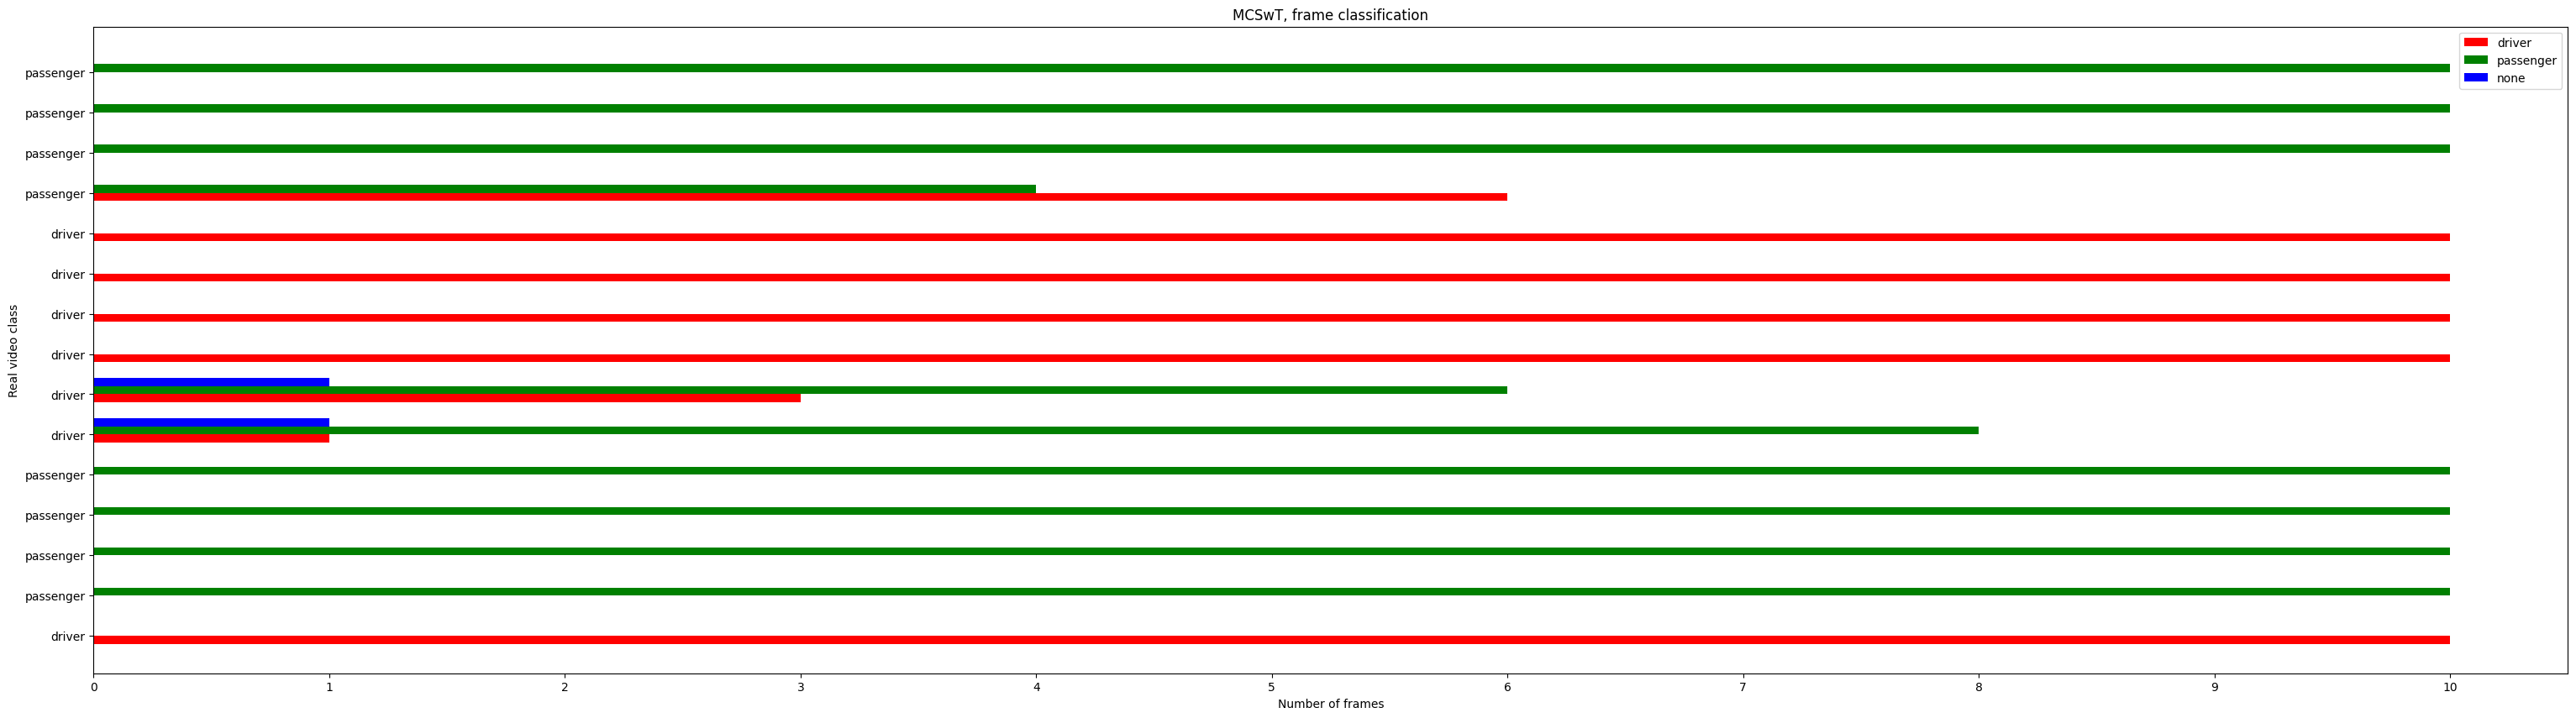

In [46]:
# Spessore delle barre orizzontali nel grafico MCSwT
bar_height = 0.2

# Inizializzazione degli indici di asse in base al numero di elementi video
x = np.arange(len(real_video_classes))
my_xticks = real_video_classes
# Rimodella l'array delle predizioni dell'algoritmo MCSwT
y = MCSwT_predictions.reshape((n, fps * sec))

fig, ax = plt.subplots(figsize=(38, 10))
big_df_MCSwT = pd.DataFrame(columns = classes)
# Esegue la categorizzazione e il conteggio di frame per ciascun video
for video_frame_predictions in y:
  my_array = np.array([
      np.count_nonzero(video_frame_predictions == "driver"),
      np.count_nonzero(video_frame_predictions == "passenger"),
      np.count_nonzero(video_frame_predictions == "none")
    ])
  df = pd.DataFrame([my_array], columns = classes)
  big_df_MCSwT = pd.concat([big_df_MCSwT, df])

# Rappresentazione delle barre orizzontali relative ai tre stati
ax.barh(x, big_df_MCSwT["driver"], height=bar_height, color='r')
ax.barh(x+bar_height, big_df_MCSwT["passenger"], height=bar_height, color='g')
ax.barh(x+2*bar_height, big_df_MCSwT['none'], height=bar_height, color='b')
ax.set_yticks(x + bar_height / 2)
ax.set_yticklabels(real_video_classes)
ax.set_xticks(np.arange(fps * sec + 1))
ax.set(xlabel='Number of frames', ylabel='Real video class', title='MCSwT, frame classification')
ax.legend(classes)

# Salva il grafico risultante per l'euristica con soglia di attivazione
plt.savefig(f"{plot_directory}/{classifications_plot_name}_{MCSwT_plot_name}_{per_video_plot_name}.png")
plt.show()

<class 'numpy.ndarray'>


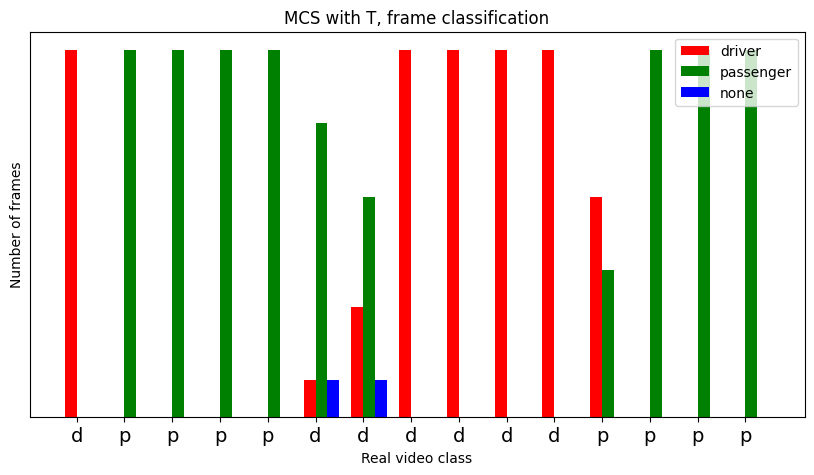

In [47]:
# Spessore delle barre verticali del grafico MCS con T
bar_height = 0.25

# Costruisce gli indici di asse
y = np.arange(len(real_video_classes))
my_xticks = real_video_classes
# Rimodella l'array di predizioni per la visualizzazione grafica
x = MCSwT_predictions.reshape((n, fps * sec))

fig, ax = plt.subplots(figsize=(10, 5))
big_df_MCSwT = pd.DataFrame(columns = classes)
# Calcola le occorrenze delle tre classi e popola la tabella riassuntiva
for video_frame_predictions in x:
  my_array = np.array([
      np.count_nonzero(video_frame_predictions == "driver"),
      np.count_nonzero(video_frame_predictions == "passenger"),
      np.count_nonzero(video_frame_predictions == "none")
    ])
  df = pd.DataFrame([my_array], columns = classes)
  big_df_MCSwT = pd.concat([big_df_MCSwT, df])

# Traccia le barre verticali per conducente, passeggero e indefinito
ax.bar(y, big_df_MCSwT["driver"], width=bar_height, color='r')
ax.bar(y+bar_height, big_df_MCSwT["passenger"], width=bar_height, color='g')
ax.bar(y+2*bar_height, big_df_MCSwT['none'], width=bar_height, color='b')
ax.set_xticks(y + bar_height / 2)
f = lambda x: x[0]
my_func = np.vectorize(f)
print(type(real_video_classes))
ax.set_xticklabels(my_func(real_video_classes), fontsize=14)
ax.set_yticks([])
ax.set(ylabel='Number of frames', xlabel='Real video class', title='MCS with T, frame classification')
ax.legend(classes)

# Esporta l'immagine PNG del plot finale verticalizzato
plt.savefig(f"{plot_directory}/{classifications_plot_name}_{MCSwT_plot_name}_{per_video_plot_name}_horizontal.png")
plt.show()

# Grafici su dati aggregati
Considereremo la classe $\text{driver}$ come $\text{positives}$ e la classe $\text{passenger}$ come $\text{negatives}$.
## Accuracy
Si ricorda che l'accuratezza misura la frazione di predizioni corrette rispetto al numero totale di predizioni: \\
$ \text{Accuracy} = \frac{\text{correct_classifications}}{\text{all_classifications}} $

## Precision
Si ricorda che la precisione misura la frazione di predizioni positive corrette rispetto al numero totale di predizioni positive effettuate dal modello: \\
$ \text{Precision} = \frac{\text{true_posivites}}{\text{true_positives} + \text{false_positives}}$

## Recall
Si ricorda che la recall misura la frazione di predizioni positive corrette rispetto al numero totale di positivi reali: \\
$ \text{Precision} = \frac{\text{true_positives}}{\text{true_positives} + \text{false_negatives}} $

Nel nostro specifico caso d'uso, queste metriche possono essere interpretate nel seguente modo:
- accuracy: *quanti frame sono stati classificati correttamente?*
- precision: *dei frame classificati come guidatori, quanti sono veramente guidatori?*
- recall: *dei frame da guidatore, quanti siamo riusciti a classificare correttamente come guidatori?*

Viene naturale ritenere più importante avere un'alta recall, piuttosto che un'alta precision, perchè vogliamo ridurre al minor valore possibile il numero di guidatori non riconosciuti.

In [48]:
# Numero complessivo di immagini/fotogrammi su cui viene eseguita la pipeline di predizione per video
frames = fps * sec

In [49]:
# Inizializza a zero la variabile di controllo x
x = 0

# Rimodella l'array delle predizioni di MCSwT in una matrice con n righe e numero di frame per video
y_activation_predictions = MCSwT_predictions.reshape((n, fps * sec))
# Rimodella l'array delle predizioni di MCS in una matrice n x frame totali
y_MCS_predictions = MCS_predictions.reshape((n, fps * sec))
# Rimodella l'array delle predizioni di baseline in una matrice n x frame totali
y_cc_predictions = baseline_predictions.reshape((n, fps * sec))

# Definisce la stringa identificativa per la classe positiva
positive_class = "driver"
# Definisce la stringa identificativa per la classe negativa
negative_class = "passenger"

# Inizializza array vuoti per registrare l'accuratezza di ogni video per le tre euristiche
acc_per_vid_MCSwT_array = np.empty(0)
# Inizializza l'array delle accuratezze per video di MCS
acc_per_vid_mcs_array = np.empty(0)
# Inizializza l'array delle accuratezze per video della baseline
acc_per_vid_cc_predictions_array = np.empty(0)

# Crea un dizionario per raccogliere i conteggi di True Positives, False Positives e False Negatives
tp_fp_fn_dict = {}
# Cicla sulle euristiche per inizializzare i rispettivi dizionari di conteggio metriche
for heuristic in heuristics:
  # Configura a zero i contatori TP, FP e FN per l'euristica corrente
  tp_fp_fn_dict[heuristic] = { "TP": 0, "FP": 0, "FN": 0 }

# Cicla su ciascun video nel dataset per calcolare le metriche frame per frame
for index in range(0, len(y_activation_predictions)):
  # Estrae le predizioni dei frame del video corrente per MCSwT
  video_frame_predictions_activation_predictions = y_activation_predictions[index]
  # Estrae le predizioni dei frame del video corrente per MCS
  video_frame_predictions_MCS_predictions = y_MCS_predictions[index]
  # Estrae le predizioni dei frame del video corrente per la baseline
  video_frame_predictions_cc_predictions = y_cc_predictions[index]

  # Calcola l'accuratezza del video corrente per MCSwT confrontando le predizioni con la classe reale
  vid_acc_MCSwT = np.count_nonzero(video_frame_predictions_activation_predictions == real_video_classes[index]) / frames
  # Calcola l'accuratezza del video corrente per MCS
  vid_acc_mcs = np.count_nonzero(video_frame_predictions_MCS_predictions == real_video_classes[index]) / frames
  # Calcola l'accuratezza del video corrente per la baseline
  vid_acc_cc_predictions = np.count_nonzero(video_frame_predictions_cc_predictions == real_video_classes[index]) / frames

  # Aggiunge l'accuratezza calcolata per MCSwT al corrispondente array di riepilogo
  acc_per_vid_MCSwT_array = np.append(acc_per_vid_MCSwT_array, vid_acc_MCSwT)
  # Aggiunge l'accuratezza calcolata per MCS al corrispondente array
  acc_per_vid_mcs_array = np.append(acc_per_vid_mcs_array, vid_acc_mcs)
  # Aggiunge l'accuratezza calcolata per la baseline al corrispondente array
  acc_per_vid_cc_predictions_array = np.append(acc_per_vid_cc_predictions_array, vid_acc_cc_predictions)

  # Analizza ogni singolo frame del video per determinare e classificare TP, FP e FN
  for frame_index in range(len(video_frame_predictions_activation_predictions)):
    # Verifica se la predizione MCS e la classe reale corrispondono alla classe positiva (True Positive)
    if video_frame_predictions_MCS_predictions[frame_index] == positive_class and real_video_classes[index] == positive_class:
      # Incrementa i True Positives per MCS
      tp_fp_fn_dict[MCS_name]["TP"] += 1
    # Verifica se la predizione MCS è positiva ma la classe reale è negativa (False Positive)
    elif video_frame_predictions_MCS_predictions[frame_index] == positive_class and real_video_classes[index] == negative_class:
      # Incrementa i False Positives per MCS
      tp_fp_fn_dict[MCS_name]["FP"] += 1
    # Verifica se la predizione MCS è negativa ma la classe reale è positiva (False Negative)
    elif video_frame_predictions_MCS_predictions[frame_index] == negative_class and real_video_classes[index] == positive_class:
      # Incrementa i False Negatives per MCS
      tp_fp_fn_dict[MCS_name]["FN"] += 1

    # Ripete la classificazione delle metriche per l'euristica MCSwT
    if video_frame_predictions_activation_predictions[frame_index] == positive_class and real_video_classes[index] == positive_class:
      # Incrementa i True Positives per MCSwT
      tp_fp_fn_dict[MCSwT_name]["TP"] += 1
    # Verifica se la predizione MCSwT è un False Positive
    elif video_frame_predictions_activation_predictions[frame_index] == positive_class and real_video_classes[index] == negative_class:
      # Incrementa i False Positives per MCSwT
      tp_fp_fn_dict[MCSwT_name]["FP"] += 1
    # Verifica se la predizione MCSwT è un False Negative
    elif video_frame_predictions_activation_predictions[frame_index] == negative_class and real_video_classes[index] == positive_class:
      # Incrementa i False Negatives per MCSwT
      tp_fp_fn_dict[MCSwT_name]["FN"] += 1

    # Ripete la classificazione delle metriche per l'euristica di baseline
    if video_frame_predictions_cc_predictions[frame_index] == positive_class and real_video_classes[index] == positive_class:
      # Incrementa i True Positives per la baseline
      tp_fp_fn_dict[baseline_name]["TP"] += 1
    # Verifica se la predizione della baseline è un False Positive
    elif video_frame_predictions_cc_predictions[frame_index] == positive_class and real_video_classes[index] == negative_class:
      # Incrementa i False Positives per la baseline
      tp_fp_fn_dict[baseline_name]["FP"] += 1
    # Verifica se la predizione della baseline è un False Negative
    elif video_frame_predictions_cc_predictions[frame_index] == negative_class and real_video_classes[index] == positive_class:
      # Incrementa i False Negatives per la baseline
      tp_fp_fn_dict[baseline_name]["FN"] += 1

# Calcola il valore finale di precision per l'euristica MCSwT evitando divisioni per zero
vid_prec_MCSwT = tp_fp_fn_dict[MCSwT_name]["TP"] / (tp_fp_fn_dict[MCSwT_name]["TP"] + tp_fp_fn_dict[MCSwT_name]["FP"]) if (tp_fp_fn_dict[MCSwT_name]["TP"] + tp_fp_fn_dict[MCSwT_name]["FP"]) > 0 else 0.0
# Calcola la precision per l'euristica MCS evitando divisioni per zero
vid_prec_mcs = tp_fp_fn_dict[MCS_name]["TP"] / (tp_fp_fn_dict[MCS_name]["TP"] + tp_fp_fn_dict[MCS_name]["FP"]) if (tp_fp_fn_dict[MCS_name]["TP"] + tp_fp_fn_dict[MCS_name]["FP"]) > 0 else 0.0
# Calcola la precision per l'euristica baseline evitando divisioni per zero
vid_prec_cc = tp_fp_fn_dict[baseline_name]["TP"] / (tp_fp_fn_dict[baseline_name]["TP"] + tp_fp_fn_dict[baseline_name]["FP"]) if (tp_fp_fn_dict[baseline_name]["TP"] + tp_fp_fn_dict[baseline_name]["FP"]) > 0 else 0.0

# Calcola il valore finale di recall per l'euristica MCSwT evitando divisioni per zero
vid_rec_MCSwT = tp_fp_fn_dict[MCSwT_name]["TP"] / (tp_fp_fn_dict[MCSwT_name]["TP"] + tp_fp_fn_dict[MCSwT_name]["FN"]) if (tp_fp_fn_dict[MCSwT_name]["TP"] + tp_fp_fn_dict[MCSwT_name]["FN"]) > 0 else 0.0
# Calcola la recall per l'euristica MCS evitando divisioni per zero
vid_rec_mcs = tp_fp_fn_dict[MCS_name]["TP"] / (tp_fp_fn_dict[MCS_name]["TP"] + tp_fp_fn_dict[MCS_name]["FN"]) if (tp_fp_fn_dict[MCS_name]["TP"] + tp_fp_fn_dict[MCS_name]["FN"]) > 0 else 0.0
# Calcola la recall per l'euristica baseline evitando divisioni per zero
vid_rec_cc = tp_fp_fn_dict[baseline_name]["TP"] / (tp_fp_fn_dict[baseline_name]["TP"] + tp_fp_fn_dict[baseline_name]["FN"]) if (tp_fp_fn_dict[baseline_name]["TP"] + tp_fp_fn_dict[baseline_name]["FN"]) > 0 else 0.0

# Accuracy

[np.float64(79.33333333333333), np.float64(87.33333333333333), np.float64(85.33333333333334)]


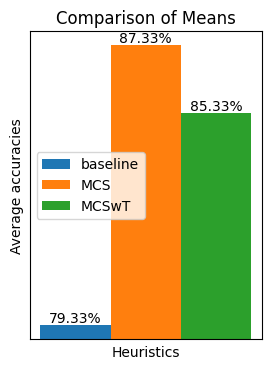

In [50]:
bar_width = 0.001
# Calcoliamo la media delle accuracy
accuracy = [mean(acc_per_vid_cc_predictions_array) * 100, mean(acc_per_vid_mcs_array) * 100, mean(acc_per_vid_MCSwT_array) * 100]
print(accuracy)
fig, ax = plt.subplots(figsize=(3, 4))
for k in range(0, len(heuristics)):
  bar_container = ax.bar(x + (k * bar_width), accuracy[k], width=bar_width)
  ax.bar_label(bar_container, fmt='{:,.2f}%', fontsize=10)
ax.set(xlabel='Heuristics', ylabel='Average accuracies', title='Comparison of Means')
ax.set_yscale('log')
ax.legend(heuristics, loc='center left')
ax.set_xticks([])
plt.minorticks_off()


plt.savefig(f"{plot_directory}/{classifications_plot_name}_accuracy_log_scale.png")
plt.show()

## Precision

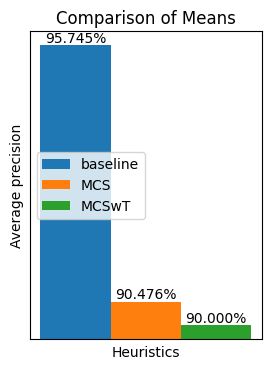

In [51]:
# Costruiamo le liste da visualizzare per la precision e recall basandoci sulle euristiche applicate
precision = [vid_prec_cc * 100, vid_prec_mcs * 100, vid_prec_MCSwT * 100]

# Inizializziamo il grafico
fig, ax = plt.subplots(figsize=(3, 4))
# Disegna una barra verticale per ciascun valore di precision
for k in range(0, len(heuristics)):
  bar_container = ax.bar(x + (k * bar_width), precision[k], width=bar_width)
  # Mostra l'etichetta con la percentuale formattata sopra ciascuna barra
  ax.bar_label(bar_container, fmt='{:,.3f}%', fontsize=10)
ax.set(xlabel='Heuristics', ylabel='Average precision', title='Comparison of Means')
ax.legend(heuristics, loc='center left')
# Utilizza la scala logaritmica sull'asse y per evidenziare piccole differenze percentuali
ax.set_yscale('log')
ax.set_xticks([])
plt.minorticks_off()

# Salva il grafico della precision logaritmico e lo mostra a schermo
plt.savefig(f"{plot_directory}/{classifications_plot_name}_precision_log_scale.png")
plt.show()

## Recall

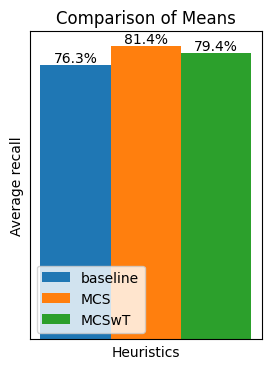

In [52]:
# Costruiamo la lista contenente i valori di recall espressi in percentuale per ciascuna euristica
recall = [vid_rec_cc * 100, vid_rec_mcs * 100, vid_rec_MCSwT * 100]

# Inizializziamo il grafico
fig, ax = plt.subplots(figsize=(3, 4))
# Plotta le barre verticali per la recall di ciascun metodo
for k in range(0, len(heuristics)):
  bar_container = ax.bar(x + (k * bar_width), recall[k], width=bar_width)
  # Mostra i valori esatti di recall calcolati direttamente sopra ogni barra
  ax.bar_label(bar_container, fmt='{:,.1f}%', fontsize=10)
ax.set(xlabel='Heuristics', ylabel='Average recall', title='Comparison of Means')
ax.legend(heuristics, loc='lower left')
ax.set_xticks([])
ax.set_yticks([])
plt.minorticks_off()

# Salva il plot della recall
plt.savefig(f"{plot_directory}/{classifications_plot_name}_recall_log_scale.png")
plt.show()

In [53]:
# Monta nuovamente il servizio di archiviazione Google Drive per l'esportazione persistente dei risultati
drive.mount('/content/gdrive')
# Crea in maniera ricorsiva la cartella di destinazione su Google Drive includendo i parametri della finestra temporale e dell'euristica
!mkdir -p /content/gdrive/MyDrive/tesi/plots/plots-srw{start_recording_window}-ws{window_size}-{special}-mcs-with-cc/{weigth_filename}
# Copia tutti i grafici PNG generati nella sottocartella appena creata per una conservazione sicura e ordinata
!cp {plot_directory}/*.png /content/gdrive/MyDrive/tesi/plots/plots-srw{start_recording_window}-ws{window_size}-{special}-mcs-with-cc/{weigth_filename}
# Crea una cartella di backup generica per i grafici associati al nome del file dei pesi del modello
!mkdir /content/gdrive/MyDrive/tesi/plots/{weigth_filename}
# Copia i grafici anche in questa seconda directory di backup su Google Drive
!cp {plot_directory}/*.png /content/gdrive/MyDrive/tesi/plots/{weigth_filename}

# Sgancia in sicurezza l'unità virtuale di Google Drive sincronizzando i file in sospeso
drive.flush_and_unmount()

Mounted at /content/gdrive
